# ĐỒ ÁN TRÍ TUỆ NHÂN TẠO: PHÂN LOẠI KIỂU THẢM RỪNG TỪ DỮ LIỆU ĐỊA HÌNH
## Forest Cover Type Classification (UCI Dataset ID: 31)

**Mô tả**: Ứng dụng mô hình **Random Forest Classifier** kết hợp **Lấy mẫu phân tầng (Stratified Sampling)**, **Kỹ thuật tạo đặc trưng sinh thái (Ecological Feature Engineering)** và phân tích triệt tiêu (Ablation Study) để phân loại 7 kiểu thảm rừng ôn đới núi cao tại Rừng quốc gia Roosevelt, Colorado, Hoa Kỳ.

**Dữ liệu**: 581.012 ô lưới (30m × 30m), 54 đặc trưng trắc địa, 7 lớp mục tiêu.

---
**Tài liệu tham chiếu**: Xem thư mục [`docs/`](../docs/README.md) để biết chi tiết về cơ sở lý thuyết, kế hoạch thí nghiệm và dẫn chứng khoa học.

---
# BƯỚC 1: KHỞI TẠO MÔI TRƯỜNG & NẠP DỮ LIỆU
> **Mục tiêu**: Nạp dữ liệu từ file nội bộ, thẩm tra toàn vẹn (581.012 × 55, 0 giá trị thiếu), ghi lại phiên bản thư viện và đặt seed ngẫu nhiên.

## 1.1. Import thư viện & Cấu hình môi trường

In [1]:
# === THƯ VIỆN CỐT LÕI ===
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path
import warnings
import time
import os
import sys
import tracemalloc  # Đo RAM đỉnh

# === THƯ VIỆN HỌC MÁY ===
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, learning_curve
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, f1_score, precision_score, recall_score,
    make_scorer
)
from sklearn.inspection import permutation_importance
from sklearn.base import clone
import joblib

# === CẤU HÌNH HIỂN THỊ ===
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', '{:.4f}'.format)
plt.rcParams.update({
    'figure.figsize': (12, 6),
    'figure.dpi': 100,
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 12,
})
sns.set_theme(style='whitegrid', palette='deep')

# === ĐƯỜNG DẪN DỰ ÁN ===
# Notebook nằm trong notebooks/. Tìm thư mục gốc (chứa docs/ và notebooks/) để chạy được
# từ gốc dự án, từ notebooks/, hoặc trên Colab sau khi clone repo.
def _find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / 'docs').is_dir() and (p / 'notebooks').is_dir():
            return p
    return start

PROJECT_ROOT = _find_project_root(Path.cwd().resolve())
DATA_DIR = PROJECT_ROOT / 'data' / 'raw'
MODEL_DIR = PROJECT_ROOT / 'models'
FIG_DIR = PROJECT_ROOT / 'results' / 'figures'
TABLE_DIR = PROJECT_ROOT / 'results' / 'tables'
for _d in (DATA_DIR, MODEL_DIR, FIG_DIR, TABLE_DIR):
    _d.mkdir(parents=True, exist_ok=True)

# === SEED NGẪU NHIÊN TOÀN CỤC ===
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("=" * 60)
print("PHIÊN BẢN THƯ VIỆN")
print("=" * 60)
print(f"Python:       {sys.version}")
print(f"NumPy:        {np.__version__}")
print(f"Pandas:       {pd.__version__}")
import sklearn
print(f"Scikit-learn: {sklearn.__version__}")
print(f"Matplotlib:   {plt.matplotlib.__version__}")
print(f"Seaborn:      {sns.__version__}")
print(f"Hệ điều hành: {os.name} / {sys.platform}")
print(f"Random State: {RANDOM_STATE}")
print(f"Thư mục dự án: {PROJECT_ROOT}")
print("=" * 60)

PHIÊN BẢN THƯ VIỆN
Python:       3.13.5 (tags/v3.13.5:6cb20a2, Jun 11 2025, 16:15:46) [MSC v.1943 64 bit (AMD64)]
NumPy:        2.5.4
Pandas:       3.1.1
Scikit-learn: 1.9.1
Matplotlib:   3.11.2
Seaborn:      0.13.2
Hệ điều hành: nt / win32
Random State: 42
Thư mục dự án: D:\Git_Repo\Forest Cover Type Classification


## 1.2. Nạp dữ liệu từ file nội bộ

In [2]:
# === ĐỊNH NGHĨA TÊN CỘT THEO covtype.info ===
COL_NAMES = [
    'Elevation', 'Aspect', 'Slope',
    'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology',
    'Horizontal_Distance_To_Roadways',
    'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm',
    'Horizontal_Distance_To_Fire_Points',
] + [f'Wilderness_Area_{i}' for i in range(1, 5)
] + [f'Soil_Type_{i}' for i in range(1, 41)
] + ['Cover_Type']

# === NẠP DỮ LIỆU ===
# Thứ tự ưu tiên: data/raw/covtype.data → data/raw/covtype.data.gz → tải qua scikit-learn.
# sklearn.datasets.fetch_covtype() trả về đúng bảng UCI 31 (đã đối chiếu: trùng khớp từng giá trị,
# cùng thứ tự dòng với covtype.data), nên kết quả không đổi khi chạy trên Colab hoặc máy mới.
DATA_PATH = DATA_DIR / 'covtype.data'
GZ_PATH = DATA_DIR / 'covtype.data.gz'
if DATA_PATH.exists():
    print(f"Đọc dữ liệu từ: {DATA_PATH}")
    df_raw = pd.read_csv(DATA_PATH, header=None, names=COL_NAMES)
elif GZ_PATH.exists():
    print(f"Đọc dữ liệu từ: {GZ_PATH}")
    df_raw = pd.read_csv(GZ_PATH, header=None, names=COL_NAMES, compression='gzip')
else:
    from sklearn.datasets import fetch_covtype
    print("Không thấy file cục bộ → tải UCI Covertype qua sklearn.datasets.fetch_covtype()")
    _cov = fetch_covtype(as_frame=False)
    df_raw = pd.DataFrame(np.column_stack([_cov.data, _cov.target]).astype(np.int64), columns=COL_NAMES)
print(f"Kích thước dữ liệu: {df_raw.shape[0]:,} dòng × {df_raw.shape[1]} cột")

Đọc dữ liệu từ: D:\Git_Repo\Forest Cover Type Classification\data\raw\covtype.data
Kích thước dữ liệu: 581,012 dòng × 55 cột


## 1.3. Thẩm tra toàn vẹn dữ liệu

In [3]:
# === KIỂM TRA KÍCH THƯỚC ===
assert df_raw.shape == (581012, 55), \
    f"[LỖI] Kích thước không khớp: {df_raw.shape} ≠ (581012, 55)"
print(f"✓ Kích thước dữ liệu: {df_raw.shape[0]:,} × {df_raw.shape[1]} — ĐÚNG")

# === KIỂM TRA GIÁ TRỊ THIẾU ===
n_missing = df_raw.isnull().sum().sum()
assert n_missing == 0, f"[LỖI] Phát hiện {n_missing} giá trị thiếu!"
print(f"✓ Giá trị thiếu: {n_missing} — ĐÚNG")

# === KIỂM TRA PHÂN BỐ 7 LỚP ===
EXPECTED_COUNTS = {
    1: 211840, 2: 283301, 3: 35754, 4: 2747,
    5: 9493,   6: 17367,  7: 20510
}
CLASS_NAMES = {
    1: 'Spruce/Fir', 2: 'Lodgepole Pine', 3: 'Ponderosa Pine',
    4: 'Cottonwood/Willow', 5: 'Aspen', 6: 'Douglas-fir', 7: 'Krummholz'
}

actual_counts = df_raw['Cover_Type'].value_counts().sort_index()
print(f"\n{'Lớp':<6} {'Tên loài':<22} {'Số lượng':>10} {'Tỷ lệ':>10} {'Kỳ vọng':>10} {'Khớp':>6}")
print("-" * 70)
all_match = True
for cls_id in range(1, 8):
    actual = actual_counts[cls_id]
    expected = EXPECTED_COUNTS[cls_id]
    pct = actual / len(df_raw) * 100
    match = "✓" if actual == expected else "✗"
    if actual != expected:
        all_match = False
    print(f"  {cls_id:<4} {CLASS_NAMES[cls_id]:<22} {actual:>10,} {pct:>9.3f}% {expected:>10,} {match:>6}")

print("-" * 70)
print(f"  Tổng: {len(df_raw):,}")
assert all_match, "[LỖI] Phân bố lớp không khớp với tài liệu!"
print("✓ Phân bố 7 lớp khớp chính xác với covtype.info [1]")

✓ Kích thước dữ liệu: 581,012 × 55 — ĐÚNG
✓ Giá trị thiếu: 0 — ĐÚNG

Lớp    Tên loài                 Số lượng      Tỷ lệ    Kỳ vọng   Khớp
----------------------------------------------------------------------
  1    Spruce/Fir                211,840    36.461%    211,840      ✓
  2    Lodgepole Pine            283,301    48.760%    283,301      ✓
  3    Ponderosa Pine             35,754     6.154%     35,754      ✓
  4    Cottonwood/Willow           2,747     0.473%      2,747      ✓
  5    Aspen                       9,493     1.634%      9,493      ✓
  6    Douglas-fir                17,367     2.989%     17,367      ✓
  7    Krummholz                  20,510     3.530%     20,510      ✓
----------------------------------------------------------------------
  Tổng: 581,012
✓ Phân bố 7 lớp khớp chính xác với covtype.info [1]


In [4]:
# === ÉP KIỂU ĐỂ GIẢM RAM ===
print("\n--- Tối ưu kiểu dữ liệu ---")
mem_before = df_raw.memory_usage(deep=True).sum() / (1024**2)

# Các biến nhị phân (Wilderness, Soil): uint8
binary_cols = [c for c in df_raw.columns if c.startswith('Wilderness_Area') or c.startswith('Soil_Type')]
df_raw[binary_cols] = df_raw[binary_cols].astype(np.uint8)

# Cover_Type: uint8
df_raw['Cover_Type'] = df_raw['Cover_Type'].astype(np.uint8)

# Các biến trắc địa: int32 (giữ nguyên dấu cho Vertical_Distance)
numeric_cols = [c for c in df_raw.columns if c not in binary_cols + ['Cover_Type']]
for col in numeric_cols:
    if df_raw[col].min() >= 0:
        df_raw[col] = df_raw[col].astype(np.int32)
    else:
        df_raw[col] = df_raw[col].astype(np.int32)

mem_after = df_raw.memory_usage(deep=True).sum() / (1024**2)
print(f"RAM trước ép kiểu: {mem_before:.1f} MB")
print(f"RAM sau ép kiểu:   {mem_after:.1f} MB")
print(f"Giảm:              {(1 - mem_after/mem_before)*100:.1f}%")

print("\n--- Thông tin DataFrame ---")
print(df_raw.dtypes.value_counts())
df_raw.head(3)


--- Tối ưu kiểu dữ liệu ---
RAM trước ép kiểu: 243.8 MB
RAM sau ép kiểu:   47.1 MB
Giảm:              80.7%

--- Thông tin DataFrame ---
uint8    45
int32    10
Name: count, dtype: int64


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,Wilderness_Area_1,Wilderness_Area_2,Wilderness_Area_3,Wilderness_Area_4,Soil_Type_1,Soil_Type_2,Soil_Type_3,Soil_Type_4,Soil_Type_5,Soil_Type_6,Soil_Type_7,Soil_Type_8,Soil_Type_9,Soil_Type_10,Soil_Type_11,Soil_Type_12,Soil_Type_13,Soil_Type_14,Soil_Type_15,Soil_Type_16,Soil_Type_17,Soil_Type_18,Soil_Type_19,Soil_Type_20,Soil_Type_21,Soil_Type_22,Soil_Type_23,Soil_Type_24,Soil_Type_25,Soil_Type_26,Soil_Type_27,Soil_Type_28,Soil_Type_29,Soil_Type_30,Soil_Type_31,Soil_Type_32,Soil_Type_33,Soil_Type_34,Soil_Type_35,Soil_Type_36,Soil_Type_37,Soil_Type_38,Soil_Type_39,Soil_Type_40,Cover_Type
0,2596,51,3,258,0,510,221,232,148,6279,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2


---
# BƯỚC 2: PHÂN TÍCH KHÁM PHÁ DỮ LIỆU (EDA)
> **Mục tiêu**: Minh chứng mất cân bằng lớp, kiểm tra phân bố cao độ theo đai sinh thái (đối chiếu Peet 1981, Marr 1961), xác minh quy ước dấu Vertical_Distance_To_Hydrology, và khám phá tương quan giữa các biến trắc địa.

## 2.1. Phân bố 7 kiểu thảm rừng & Mức độ mất cân bằng lớp

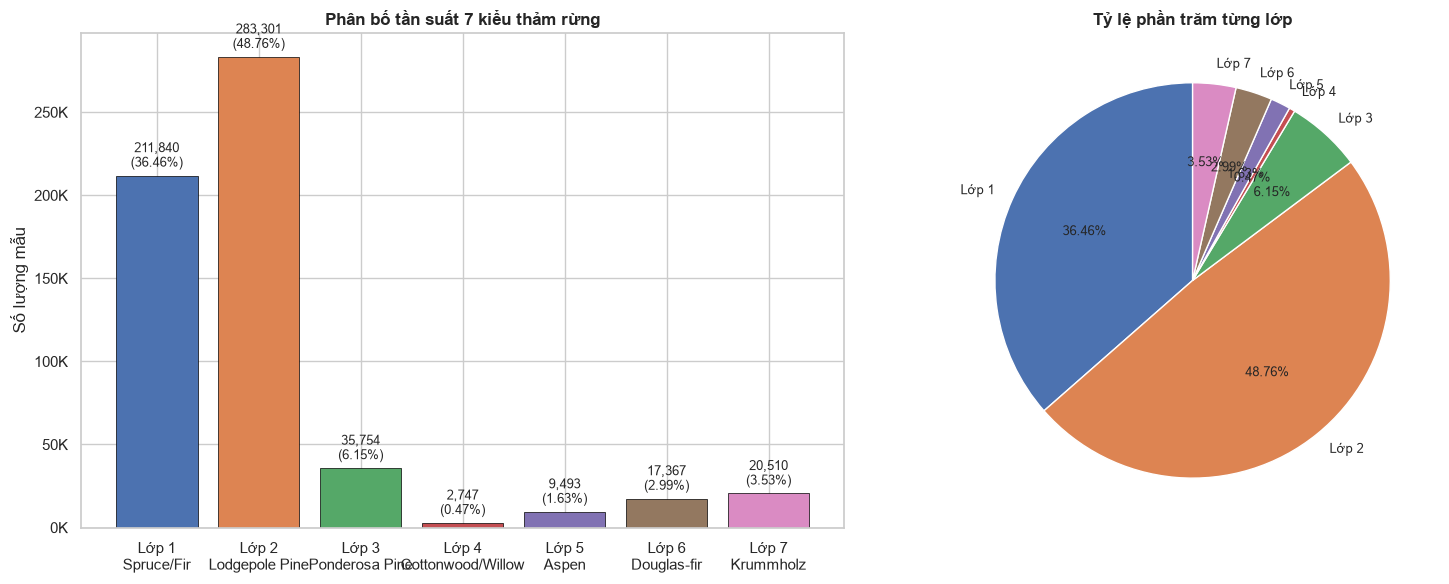


--- Mức độ mất cân bằng ---
Hai lớp đa số (1+2): 495,141 mẫu (85.22%)
Lớp thiểu số (4):    2,747 mẫu (0.473%)
Tỷ số đa số/thiểu số: 180:1


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Biểu đồ cột phân bố lớp ---
class_counts = df_raw['Cover_Type'].value_counts().sort_index()
colors = sns.color_palette('deep', 7)
bars = axes[0].bar(
    [f"Lớp {i}\n{CLASS_NAMES[i]}" for i in range(1, 8)],
    [class_counts[i] for i in range(1, 8)],
    color=colors, edgecolor='black', linewidth=0.5
)
for bar, cls_id in zip(bars, range(1, 8)):
    count = class_counts[cls_id]
    pct = count / len(df_raw) * 100
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 3000,
                 f'{count:,}\n({pct:.2f}%)', ha='center', va='bottom', fontsize=9)
axes[0].set_title('Phân bố tần suất 7 kiểu thảm rừng', fontweight='bold')
axes[0].set_ylabel('Số lượng mẫu')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1000:.0f}K'))

# --- Biểu đồ tròn tỷ lệ ---
axes[1].pie(
    [class_counts[i] for i in range(1, 8)],
    labels=[f"Lớp {i}" for i in range(1, 8)],
    autopct='%1.2f%%', colors=colors, startangle=90,
    textprops={'fontsize': 9}
)
axes[1].set_title('Tỷ lệ phần trăm từng lớp', fontweight='bold')

plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

# --- Báo cáo mất cân bằng ---
majority = class_counts[1] + class_counts[2]
minority = class_counts[4]
print(f"\n--- Mức độ mất cân bằng ---")
print(f"Hai lớp đa số (1+2): {majority:,} mẫu ({majority/len(df_raw)*100:.2f}%)")
print(f"Lớp thiểu số (4):    {minority:,} mẫu ({minority/len(df_raw)*100:.3f}%)")
print(f"Tỷ số đa số/thiểu số: {majority/minority:.0f}:1")

## 2.2. Phân bố cao độ (Elevation) theo kiểu rừng — Đối chiếu đai sinh thái

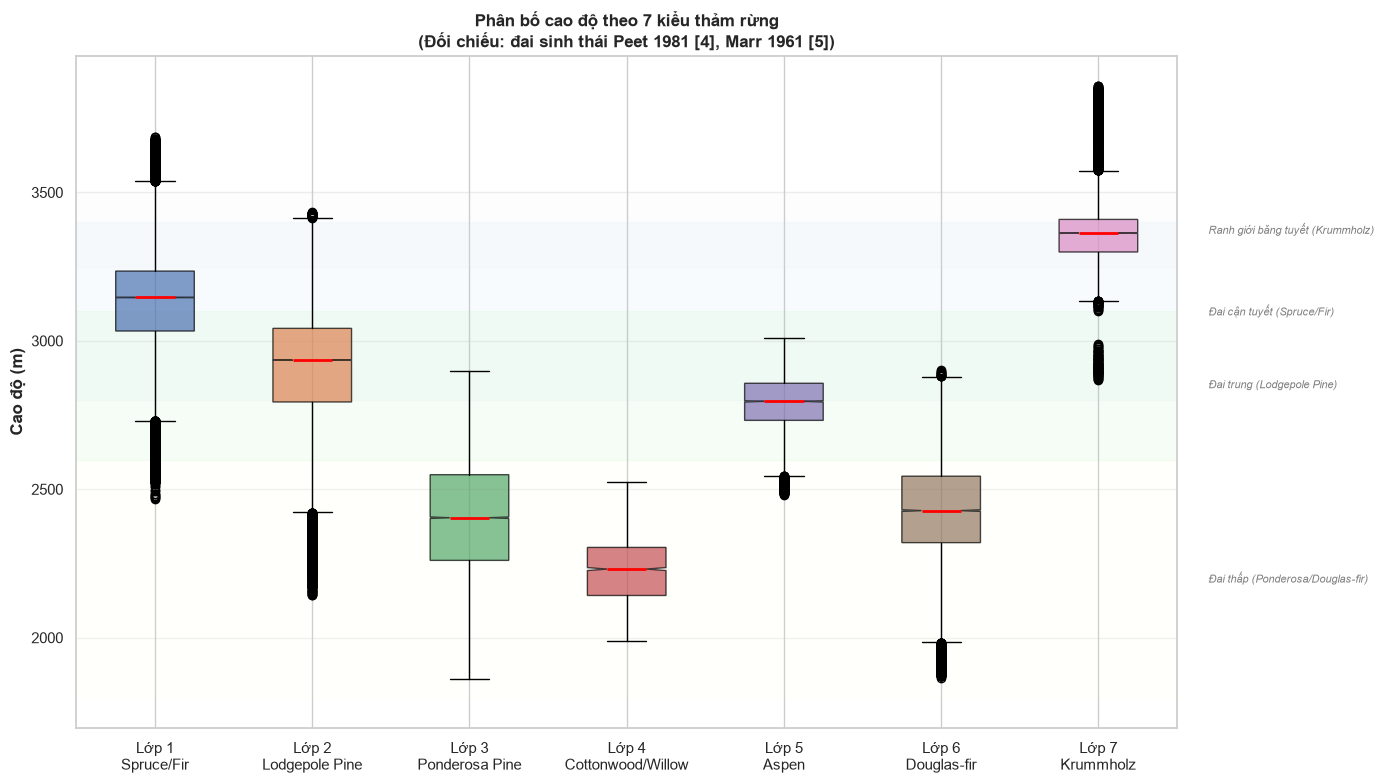


--- Thống kê mô tả Elevation theo kiểu rừng ---


,mean,std,min,25%,50%,75%,max
Lớp 1 (Spruce/Fir),3128.6449,157.8055,2466.0000,3033.0000,3146.0000,3235.0000,3686.0000
Lớp 2 (Lodgepole Pine),2920.9361,186.5794,2142.0000,2794.0000,2935.0000,3042.0000,3433.0000
Lớp 3 (Ponderosa Pine),2394.5098,196.7324,1859.0000,2260.2500,2404.0000,2549.0000,2899.0000
Lớp 4 (Cottonwood/Willow),2223.9399,102.5246,1988.0000,2142.0000,2231.0000,2304.0000,2526.0000
Lớp 5 (Aspen),2787.4176,96.5940,2482.0000,2732.0000,2796.0000,2857.0000,3011.0000
Lớp 6 (Douglas-fir),2419.1819,188.7623,1863.0000,2320.0000,2428.0000,2544.0000,2900.0000
Lớp 7 (Krummholz),3361.9287,106.9153,2868.0000,3299.2500,3363.0000,3409.0000,3858.0000


In [6]:
fig, ax = plt.subplots(figsize=(14, 8))

# --- Boxplot cao độ theo kiểu rừng ---
data_for_boxplot = [
    df_raw[df_raw['Cover_Type'] == i]['Elevation'].values
    for i in range(1, 8)
]
bp = ax.boxplot(
    data_for_boxplot,
    tick_labels=[f"Lớp {i}\n{CLASS_NAMES[i]}" for i in range(1, 8)],
    patch_artist=True, notch=True,
    medianprops=dict(color='red', linewidth=2)
)
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.set_ylabel('Cao độ (m)', fontweight='bold')
ax.set_title('Phân bố cao độ theo 7 kiểu thảm rừng\n'
             '(Đối chiếu: đai sinh thái Peet 1981 [4], Marr 1961 [5])',
             fontweight='bold')
ax.grid(axis='y', alpha=0.3)

# --- Thêm các đai sinh thái tham khảo từ văn liệu ---
ecology_bands = [
    (1800, 2600, 'Đai thấp (Ponderosa/Douglas-fir)', 'lightyellow'),
    (2600, 3100, 'Đai trung (Lodgepole Pine)', 'lightgreen'),
    (2800, 3400, 'Đai cận tuyết (Spruce/Fir)', 'lightblue'),
    (3250, 3500, 'Ranh giới băng tuyết (Krummholz)', 'lavender'),
]
for ymin, ymax, label, fcolor in ecology_bands:
    ax.axhspan(ymin, ymax, alpha=0.08, color=fcolor)
    ax.text(7.7, (ymin + ymax)/2, label, fontsize=8, va='center',
            fontstyle='italic', color='gray')

plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_elevation_boxplot.png', dpi=150, bbox_inches='tight')
plt.show()

# --- Thống kê mô tả cao độ theo lớp ---
elevation_stats = df_raw.groupby('Cover_Type')['Elevation'].describe()
elevation_stats.index = [f"Lớp {i} ({CLASS_NAMES[i]})" for i in range(1, 8)]
print("\n--- Thống kê mô tả Elevation theo kiểu rừng ---")
elevation_stats[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]

## 2.3. Kiểm tra quy ước dấu của Vertical_Distance_To_Hydrology

--- Thống kê Vertical_Distance_To_Hydrology ---
Min:    -173
Max:    601
Mean:   46.42
Median: 30.0
Số mẫu < 0: 55,143 (9.5%)
Số mẫu = 0: 38,665 (6.7%)
Số mẫu > 0: 487,204 (83.9%)


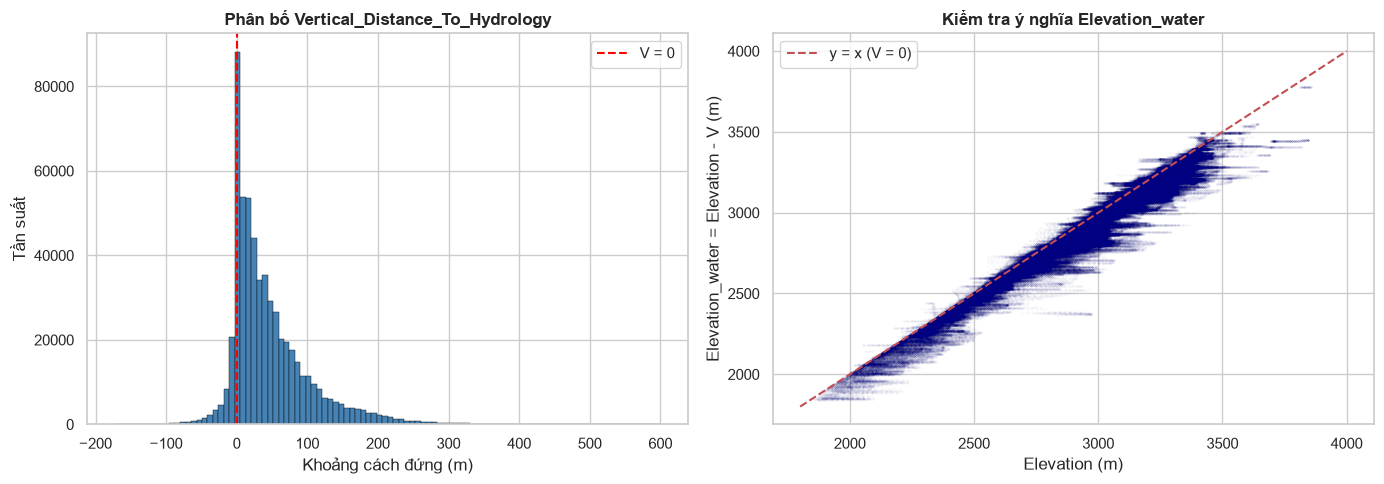


=> Kết luận: V > 0 ⟹ điểm đo nằm CAO hơn nguồn nước (trên sườn dốc)
   V < 0 ⟹ điểm đo nằm THẤP hơn nguồn nước (đáy khe)
   Elevation_water = Elevation - V: cao độ tuyệt đối của nguồn nước mặt gần nhất


In [7]:
vdth = df_raw['Vertical_Distance_To_Hydrology']
print("--- Thống kê Vertical_Distance_To_Hydrology ---")
print(f"Min:    {vdth.min()}")
print(f"Max:    {vdth.max()}")
print(f"Mean:   {vdth.mean():.2f}")
print(f"Median: {vdth.median():.1f}")
print(f"Số mẫu < 0: {(vdth < 0).sum():,} ({(vdth < 0).mean()*100:.1f}%)")
print(f"Số mẫu = 0: {(vdth == 0).sum():,} ({(vdth == 0).mean()*100:.1f}%)")
print(f"Số mẫu > 0: {(vdth > 0).sum():,} ({(vdth > 0).mean()*100:.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(vdth, bins=100, edgecolor='black', linewidth=0.3, color='steelblue')
axes[0].axvline(0, color='red', linestyle='--', label='V = 0')
axes[0].set_title('Phân bố Vertical_Distance_To_Hydrology', fontweight='bold')
axes[0].set_xlabel('Khoảng cách đứng (m)')
axes[0].set_ylabel('Tần suất')
axes[0].legend()

# Scatter: Elevation vs Elevation_water
elev_water = df_raw['Elevation'] - vdth
axes[1].scatter(df_raw['Elevation'], elev_water, s=0.05, alpha=0.1, c='navy')
axes[1].plot([1800, 4000], [1800, 4000], 'r--', label='y = x (V = 0)')
axes[1].set_xlabel('Elevation (m)')
axes[1].set_ylabel('Elevation_water = Elevation - V (m)')
axes[1].set_title('Kiểm tra ý nghĩa Elevation_water', fontweight='bold')
axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_vertical_distance.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n=> Kết luận: V > 0 ⟹ điểm đo nằm CAO hơn nguồn nước (trên sườn dốc)")
print("   V < 0 ⟹ điểm đo nằm THẤP hơn nguồn nước (đáy khe)")
print("   Elevation_water = Elevation - V: cao độ tuyệt đối của nguồn nước mặt gần nhất")

## 2.4. Ma trận tương quan giữa các biến trắc địa liên tục

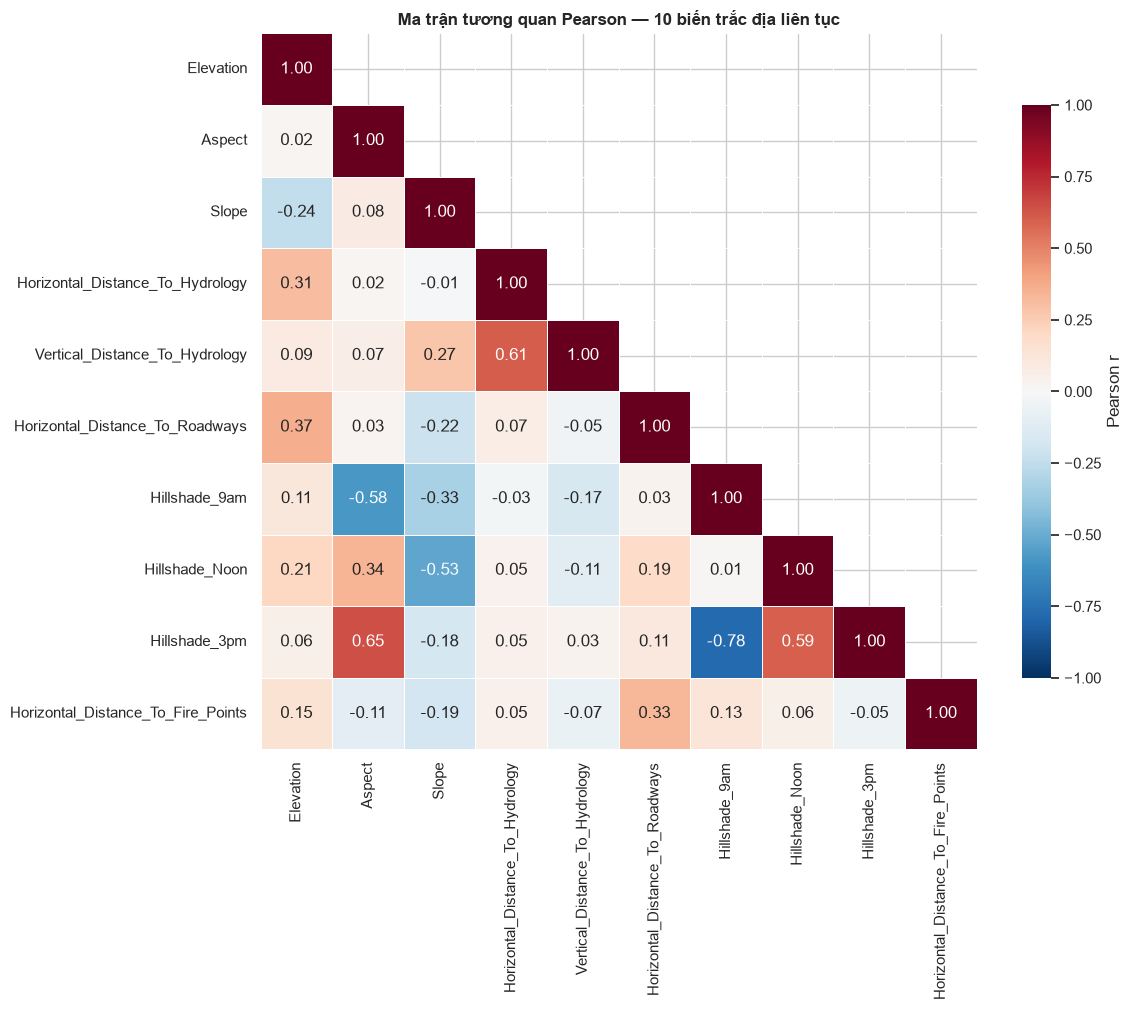


--- Các cặp tương quan |r| > 0.5 ---
                                    Aspect ↔ Hillshade_9am                           : r = -0.579
                                    Aspect ↔ Hillshade_3pm                           : r = 0.647
                                     Slope ↔ Hillshade_Noon                          : r = -0.527
          Horizontal_Distance_To_Hydrology ↔ Vertical_Distance_To_Hydrology          : r = 0.606
                             Hillshade_9am ↔ Hillshade_3pm                           : r = -0.780
                            Hillshade_Noon ↔ Hillshade_3pm                           : r = 0.594


In [8]:
continuous_cols = [
    'Elevation', 'Aspect', 'Slope',
    'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology',
    'Horizontal_Distance_To_Roadways',
    'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm',
    'Horizontal_Distance_To_Fire_Points'
]

corr_matrix = df_raw[continuous_cols].corr()

fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(
    corr_matrix, mask=mask, annot=True, fmt='.2f',
    cmap='RdBu_r', center=0, vmin=-1, vmax=1,
    square=True, linewidths=0.5, ax=ax,
    cbar_kws={'shrink': 0.8, 'label': 'Pearson r'}
)
ax.set_title('Ma trận tương quan Pearson — 10 biến trắc địa liên tục', fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_correlation_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

# --- Các cặp tương quan cao đáng chú ý ---
print("\n--- Các cặp tương quan |r| > 0.5 ---")
for i in range(len(continuous_cols)):
    for j in range(i+1, len(continuous_cols)):
        r = corr_matrix.iloc[i, j]
        if abs(r) > 0.5:
            print(f"  {continuous_cols[i]:>40s} ↔ {continuous_cols[j]:<40s}: r = {r:.3f}")

## 2.5. Phân bố Wilderness Area và mối liên hệ với Cover Type

--- Bảng chéo Cover_Type × Wilderness_Area ---
Wilderness_Code            WA1 (Rawah)  WA2 (Neota)  WA3 (Comanche Peak)  WA4 (Cache la Poudre)     All
Cover_Type                                                                                             
Lớp 1 (Spruce/Fir)              105717        18595                87528                      0  211840
Lớp 2 (Lodgepole Pine)          146197         8985               125093                   3026  283301
Lớp 3 (Ponderosa Pine)               0            0                14300                  21454   35754
Lớp 4 (Cottonwood/Willow)            0            0                    0                   2747    2747
Lớp 5 (Aspen)                     3781            0                 5712                      0    9493
Lớp 6 (Douglas-fir)                  0            0                 7626                   9741   17367
Lớp 7 (Krummholz)                 5101         2304                13105                      0   20510
All              

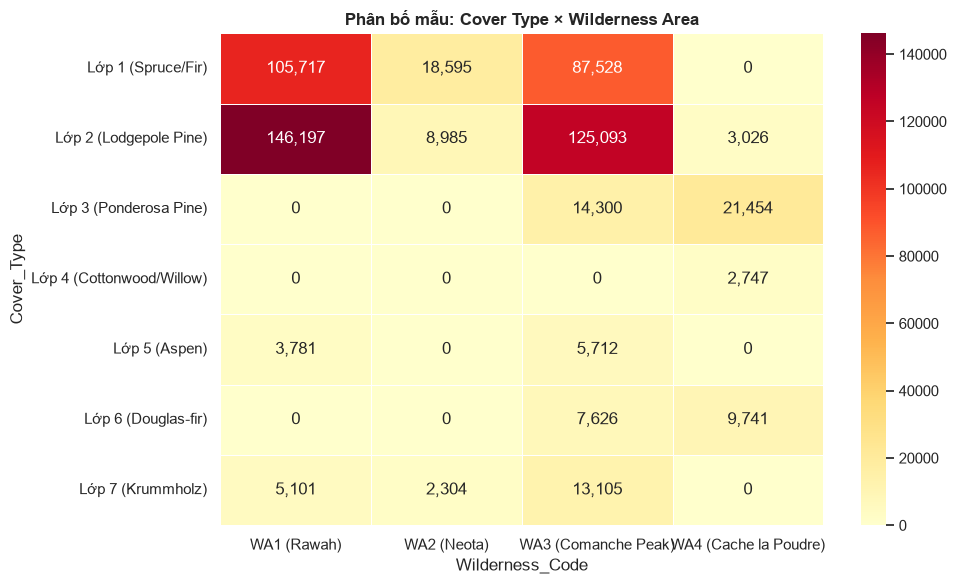


Nhận xét:
- Lớp 3 (Ponderosa Pine), Lớp 4 (Cottonwood/Willow), Lớp 6 (Douglas-fir)
  tập trung chủ yếu ở WA4 (Cache la Poudre) — vùng đai thấp nhất.
- Lớp 7 (Krummholz) tập trung ở WA2 (Neota) — vùng đai cao nhất.


In [9]:
# --- Thống kê Wilderness Area ---
wa_cols = [f'Wilderness_Area_{i}' for i in range(1, 5)]
wa_names = {1: 'Rawah', 2: 'Neota', 3: 'Comanche Peak', 4: 'Cache la Poudre'}

wa_code = df_raw[wa_cols].values.argmax(axis=1) + 1
df_raw['Wilderness_Code'] = wa_code.astype(np.uint8)

# Crosstab
ct = pd.crosstab(
    df_raw['Cover_Type'].map(lambda x: f"Lớp {x} ({CLASS_NAMES[x]})"),
    df_raw['Wilderness_Code'].map(lambda x: f"WA{x} ({wa_names[x]})"),
    margins=True
)
print("--- Bảng chéo Cover_Type × Wilderness_Area ---")
print(ct.to_string())

# Heatmap
fig, ax = plt.subplots(figsize=(10, 6))
ct_no_margin = ct.iloc[:-1, :-1].astype(int)
sns.heatmap(ct_no_margin, annot=True, fmt=',', cmap='YlOrRd', ax=ax, linewidths=0.5)
ax.set_title('Phân bố mẫu: Cover Type × Wilderness Area', fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_crosstab_wa.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nNhận xét:")
print("- Lớp 3 (Ponderosa Pine), Lớp 4 (Cottonwood/Willow), Lớp 6 (Douglas-fir)")
print("  tập trung chủ yếu ở WA4 (Cache la Poudre) — vùng đai thấp nhất.")
print("- Lớp 7 (Krummholz) tập trung ở WA2 (Neota) — vùng đai cao nhất.")

---
# BƯỚC 3: LẤY MẪU PHÂN TẦNG & KỸ THUẬT ĐẶC TRƯNG SINH THÁI
> **Mục tiêu**: Lấy mẫu phân tầng 15% cho pha thử nghiệm, chia Train/Test, và tạo các đặc trưng sinh thái (D_hydro, Elevation_water, Aspect sin/cos, ΔHillshade, biểu diễn thổ nhưỡng).

## 3.1. Lấy mẫu phân tầng 15% & Chia Train/Test

### Mục tiêu và chiến lược phân chia dữ liệu:
1. **Pha thử nghiệm nhanh (Mẫu 15%, $n = 87.152$)**:
   - Sử dụng kỹ thuật **Lấy mẫu phân tầng theo nhãn (Stratified Sampling)** từ toàn bộ $581.012$ mẫu với hệ số phân bổ $f = 15.0\%$.
   - Mục đích: Tiết kiệm tài nguyên và thời gian tính toán trong các pha thử nghiệm ablation và tinh chỉnh mô hình, đồng thời bảo toàn cấu trúc phân bố nguyên bản của cả 7 kiểu thảm rừng.
2. **Tập kiểm thử độc lập (Test Set 20%, $n = 17.431$)**:
   - Trích xuất phân tầng từ tập Mẫu 15% để làm tập đánh giá khách quan cho quá trình lựa chọn mô hình và đặc trưng.
3. **Tập huấn luyện (Train Set 80%, $n = 69.721$)**:
   - Dùng để huấn luyện mô hình và thực hiện kiểm định chéo (Cross-Validation). Mọi phép tính trọng số lớp (`class_weight`) chỉ được tính toán trên tập này.
4. **Tập Hold-out lớn (85% còn lại, $n = 493.860$)**:
   - Hoàn toàn độc lập, không tham gia vào bất kỳ khâu huấn luyện hay tinh chỉnh siêu tham số nào.
   - Được bảo lưu nguyên vẹn để: (1) Đánh giá năng lực tổng quát hóa cuối cùng ở Bước 5; (2) Làm bể truy vấn dữ liệu độc lập phục vụ trích xuất cây đại diện (Surrogate Tree) ở Bước 6.

In [10]:
# === PHÂN CHIA DỮ LIỆU ===
from IPython.display import display

X_all = df_raw.drop(columns=['Cover_Type'])
y_all = df_raw['Cover_Type']

# 1. Trích xuất Mẫu 15% cho pha thử nghiệm nhanh và bảo lưu 85% làm Hold-out lớn
SAMPLING_FRACTION = 0.15
X_sample, X_holdout, y_sample, y_holdout = train_test_split(
    X_all, y_all,
    train_size=SAMPLING_FRACTION,
    stratify=y_all,
    random_state=RANDOM_STATE
)

# 2. Phân chia tập Mẫu 15% thành Train (80%) và Test (20%) có phân tầng
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_sample, y_sample,
    test_size=0.20,
    stratify=y_sample,
    random_state=RANDOM_STATE
)

# --- BẢNG 1: TỔNG QUAN QUY MÔ VÀ VAI TRÒ CỦA CÁC TẬP DỮ LIỆU ---
summary_data = [
    {
        'Tập dữ liệu': 'Tổng thể ban đầu (Toàn bộ)',
        'Ký hiệu': 'df_raw',
        'Số lượng mẫu (N)': f"{len(df_raw):,}",
        'Tỷ lệ tổng thể (%)': "100.00%",
        'Vai trò / Mục đích sử dụng': 'Dữ liệu trắc địa gốc từ Rừng quốc gia Roosevelt (UCI ID 31)'
    },
    {
        'Tập dữ liệu': 'Mẫu thử nghiệm nhanh (15%)',
        'Ký hiệu': '(X_sample, y_sample)',
        'Số lượng mẫu (N)': f"{len(X_sample):,}",
        'Tỷ lệ tổng thể (%)': f"{len(X_sample) / len(df_raw) * 100:.2f}%",
        'Vai trò / Mục đích sử dụng': 'Không gian khảo sát cho pha thử nghiệm, kỹ thuật đặc trưng và ablation'
    },
    {
        'Tập dữ liệu': 'Tập Huấn luyện (Train - 80% mẫu 15%)',
        'Ký hiệu': '(X_train_raw, y_train)',
        'Số lượng mẫu (N)': f"{len(X_train_raw):,}",
        'Tỷ lệ tổng thể (%)': f"{len(X_train_raw) / len(df_raw) * 100:.2f}%",
        'Vai trò / Mục đích sử dụng': 'Huấn luyện RF, tính class_weight, kiểm định chéo Stratified 5-Fold'
    },
    {
        'Tập dữ liệu': 'Tập Kiểm thử (Test - 20% mẫu 15%)',
        'Ký hiệu': '(X_test_raw, y_test)',
        'Số lượng mẫu (N)': f"{len(X_test_raw):,}",
        'Tỷ lệ tổng thể (%)': f"{len(X_test_raw) / len(df_raw) * 100:.2f}%",
        'Vai trò / Mục đích sử dụng': 'Đánh giá khách quan hiệu năng mô hình, so sánh các cấu hình ablation'
    },
    {
        'Tập dữ liệu': 'Tập Hold-out lớn (85% còn lại)',
        'Ký hiệu': '(X_holdout, y_holdout)',
        'Số lượng mẫu (N)': f"{len(X_holdout):,}",
        'Tỷ lệ tổng thể (%)': f"{len(X_holdout) / len(df_raw) * 100:.2f}%",
        'Vai trò / Mục đích sử dụng': 'Kiểm chứng tổng quát hóa cuối cùng (Bước 5) và bể truy vấn luật XAI (Bước 6)'
    }
]

df_split_summary = pd.DataFrame(summary_data)
print("=== BẢNG 1: TỔNG QUAN PHÂN BỔ QUY MÔ DỮ LIỆU ===")
display(df_split_summary)

# --- BẢNG 2: THẨM ĐỊNH TÍNH BẢO TOÀN PHÂN BỐ TỶ LỆ 7 KIỂU THẢM RỪNG ---
stratify_rows = []
for cls_id in range(1, 8):
    count_all = int((y_all == cls_id).sum())
    pct_all = count_all / len(y_all) * 100
    
    count_smp = int((y_sample == cls_id).sum())
    pct_smp = count_smp / len(y_sample) * 100
    
    count_trn = int((y_train == cls_id).sum())
    pct_trn = count_trn / len(y_train) * 100
    
    count_tst = int((y_test == cls_id).sum())
    pct_tst = count_tst / len(y_test) * 100
    
    max_dev = max(abs(pct_smp - pct_all), abs(pct_trn - pct_all), abs(pct_tst - pct_all))
    
    stratify_rows.append({
        'Mã lớp': cls_id,
        'Tên kiểu thảm rừng': CLASS_NAMES[cls_id],
        'Toàn bộ (N)': f"{count_all:,}",
        'Toàn bộ (%)': f"{pct_all:.3f}%",
        'Mẫu 15% (N)': f"{count_smp:,}",
        'Mẫu 15% (%)': f"{pct_smp:.3f}%",
        'Train (N)': f"{count_trn:,}",
        'Train (%)': f"{pct_trn:.3f}%",
        'Test (N)': f"{count_tst:,}",
        'Test (%)': f"{pct_tst:.3f}%",
        'Độ lệch max (%)': f"{max_dev:.4f}%"
    })

df_stratify_check = pd.DataFrame(stratify_rows)
print("\n=== BẢNG 2: KIỂM ĐỊNH TÍNH BẢO TOÀN TỶ LỆ PHÂN TẦNG (STRATIFIED INTEGRITY) ===")
display(df_stratify_check)

=== BẢNG 1: TỔNG QUAN PHÂN BỔ QUY MÔ DỮ LIỆU ===


,Tập dữ liệu,Ký hiệu,Số lượng mẫu (N),Tỷ lệ tổng thể (%),Vai trò / Mục đích sử dụng
0,Tổng thể ban đầu (Toàn bộ),df_raw,"581,012",100.00%,Dữ liệu trắc địa gốc từ Rừng quốc gia Roosevel...
1,Mẫu thử nghiệm nhanh (15%),"(X_sample, y_sample)","87,151",15.00%,"Không gian khảo sát cho pha thử nghiệm, kỹ thu..."
2,Tập Huấn luyện (Train - 80% mẫu 15%),"(X_train_raw, y_train)","69,720",12.00%,"Huấn luyện RF, tính class_weight, kiểm định ch..."
3,Tập Kiểm thử (Test - 20% mẫu 15%),"(X_test_raw, y_test)","17,431",3.00%,"Đánh giá khách quan hiệu năng mô hình, so sánh..."
4,Tập Hold-out lớn (85% còn lại),"(X_holdout, y_holdout)","493,861",85.00%,Kiểm chứng tổng quát hóa cuối cùng (Bước 5) và...



=== BẢNG 2: KIỂM ĐỊNH TÍNH BẢO TOÀN TỶ LỆ PHÂN TẦNG (STRATIFIED INTEGRITY) ===


,Mã lớp,Tên kiểu thảm rừng,Toàn bộ (N),Toàn bộ (%),Mẫu 15% (N),Mẫu 15% (%),Train (N),Train (%),Test (N),Test (%),Độ lệch max (%)
0,1,Spruce/Fir,"211,840",36.461%,"31,776",36.461%,"25,420",36.460%,"6,356",36.464%,0.0033%
1,2,Lodgepole Pine,"283,301",48.760%,"42,495",48.760%,"33,996",48.761%,"8,499",48.758%,0.0020%
2,3,Ponderosa Pine,"35,754",6.154%,"5,363",6.154%,"4,290",6.153%,"1,073",6.156%,0.0020%
3,4,Cottonwood/Willow,"2,747",0.473%,412,0.473%,330,0.473%,82,0.470%,0.0024%
4,5,Aspen,"9,493",1.634%,"1,424",1.634%,"1,139",1.634%,285,1.635%,0.0011%
5,6,Douglas-fir,"17,367",2.989%,"2,605",2.989%,"2,084",2.989%,521,2.989%,0.0002%
6,7,Krummholz,"20,510",3.530%,"3,076",3.530%,"2,461",3.530%,615,3.528%,0.0019%


## 3.2. Hàm biến đổi đặc trưng sinh thái (Dùng chung cho mọi tập)

In [11]:
# === BẢNG ÁNH XẠ THỔ NHƯỠNG USFS ELU (từ covtype.info) ===
# Mã ELU 4 chữ số cho 40 loại đất
SOIL_TO_ELU = {
    1: 2702,  2: 2703,  3: 2704,  4: 2705,  5: 2706,  6: 2717,
    7: 3501,  8: 3502,  9: 4201, 10: 4703, 11: 4704, 12: 4744,
    13: 4758, 14: 5101, 15: 5151, 16: 6101, 17: 6102, 18: 6731,
    19: 7101, 20: 7102, 21: 7103, 22: 7201, 23: 7202, 24: 7700,
    25: 7701, 26: 7702, 27: 7709, 28: 7710, 29: 7745, 30: 7746,
    31: 7755, 32: 7756, 33: 7757, 34: 7790, 35: 8703, 36: 8707,
    37: 8708, 38: 8771, 39: 8772, 40: 8776,
}

# Giải mã chữ số 1 (Climatic Zone) và chữ số 2 (Geologic Zone)
SOIL_TO_CLIMATIC = {k: int(str(v)[0]) for k, v in SOIL_TO_ELU.items()}
SOIL_TO_GEOLOGIC = {k: int(str(v)[1]) for k, v in SOIL_TO_ELU.items()}

def engineer_features(df, soil_representation='onehot'):
    """
    Tạo đặc trưng sinh thái từ DataFrame đầu vào.
    
    Parameters
    ----------
    df : pd.DataFrame
        DataFrame chứa các cột trắc địa gốc (bao gồm cả Soil_Type và Wilderness_Area).
    soil_representation : str
        Cách biểu diễn thổ nhưỡng: 'onehot' (A), 'code' (B), 'zone' (C)
    
    Returns
    -------
    pd.DataFrame
        DataFrame với đặc trưng đã biến đổi.
    """
    out = df.copy()
    
    # --- 1. Khoảng cách Euclid tới nguồn nước ---
    H = out['Horizontal_Distance_To_Hydrology'].astype(np.float32)
    V = out['Vertical_Distance_To_Hydrology'].astype(np.float32)
    out['D_Hydro'] = np.sqrt(H**2 + V**2)
    
    # --- 2. Cao độ tuyệt đối nguồn nước ---
    out['Elevation_Water'] = out['Elevation'] - out['Vertical_Distance_To_Hydrology']
    
    # --- 3. Biến đổi lượng giác Aspect ---
    aspect_rad = np.deg2rad(out['Aspect'].astype(np.float32))
    out['Aspect_Cos'] = np.cos(aspect_rad).astype(np.float32)
    out['Aspect_Sin'] = np.sin(aspect_rad).astype(np.float32)
    
    # --- 4. Delta Hillshade ---
    out['Delta_Hillshade'] = (out['Hillshade_3pm'] - out['Hillshade_9am']).astype(np.int16)
    
    # --- 5. Xử lý thổ nhưỡng ---
    soil_cols = [f'Soil_Type_{i}' for i in range(1, 41)]
    
    # Luôn tạo Soil_Type_Code (cần cho 'code' và 'zone')
    soil_code = out[soil_cols].values.argmax(axis=1) + 1
    
    if soil_representation == 'onehot':
        # Giữ nguyên 40 cột One-Hot, thêm đặc trưng sinh thái
        pass
    elif soil_representation == 'code':
        # Thay 40 cột bằng 1 cột mã số nguyên
        out = out.drop(columns=soil_cols)
        out['Soil_Type_Code'] = soil_code.astype(np.uint8)
    elif soil_representation == 'zone':
        # Thay 40 cột bằng 2 cột: Climatic Zone, Geologic Zone
        out = out.drop(columns=soil_cols)
        out['Soil_Climatic_Zone'] = np.array(
            [SOIL_TO_CLIMATIC[c] for c in soil_code], dtype=np.uint8
        )
        out['Soil_Geologic_Zone'] = np.array(
            [SOIL_TO_GEOLOGIC[c] for c in soil_code], dtype=np.uint8
        )
    else:
        raise ValueError(f"soil_representation phải là 'onehot', 'code' hoặc 'zone'. Nhận: {soil_representation}")
    
    # Bỏ cột Wilderness_Code nếu có (đã tạo trong EDA)
    if 'Wilderness_Code' in out.columns:
        out = out.drop(columns=['Wilderness_Code'])
    
    return out

print("✓ Hàm engineer_features() đã sẵn sàng.")
print("  Các đặc trưng sinh thái: D_Hydro, Elevation_Water, Aspect_Cos, Aspect_Sin, Delta_Hillshade")
print("  Các phương án biểu diễn đất: 'onehot' (A), 'code' (B), 'zone' (C)")

✓ Hàm engineer_features() đã sẵn sàng.
  Các đặc trưng sinh thái: D_Hydro, Elevation_Water, Aspect_Cos, Aspect_Sin, Delta_Hillshade
  Các phương án biểu diễn đất: 'onehot' (A), 'code' (B), 'zone' (C)


## 3.3. Áp dụng biến đổi đặc trưng

In [12]:
# === ÁP DỤNG VỚI BIỂU DIỄN MẶC ĐỊNH: ONE-HOT (phương án A) ===
# Dùng cho baseline, sau đó so sánh với các phương án khác trong ablation

X_train = engineer_features(X_train_raw, soil_representation='onehot')
X_test  = engineer_features(X_test_raw,  soil_representation='onehot')

print(f"Số đặc trưng sau biến đổi (One-Hot): {X_train.shape[1]}")
print(f"Các cột mới: {[c for c in X_train.columns if c not in X_train_raw.columns]}")

# --- Chuẩn bị biến đổi cho cả hold-out (dùng ở Bước 5) ---
X_holdout_fe = engineer_features(X_holdout, soil_representation='onehot')
print(f"\nHold-out sau biến đổi: {X_holdout_fe.shape}")

# --- Liệt kê toàn bộ cột ---
print(f"\n--- Danh sách {X_train.shape[1]} đặc trưng ---")
for i, col in enumerate(X_train.columns):
    print(f"  [{i+1:>2}] {col}")

Số đặc trưng sau biến đổi (One-Hot): 59
Các cột mới: ['D_Hydro', 'Elevation_Water', 'Aspect_Cos', 'Aspect_Sin', 'Delta_Hillshade']

Hold-out sau biến đổi: (493861, 59)

--- Danh sách 59 đặc trưng ---
  [ 1] Elevation
  [ 2] Aspect
  [ 3] Slope
  [ 4] Horizontal_Distance_To_Hydrology
  [ 5] Vertical_Distance_To_Hydrology
  [ 6] Horizontal_Distance_To_Roadways
  [ 7] Hillshade_9am
  [ 8] Hillshade_Noon
  [ 9] Hillshade_3pm
  [10] Horizontal_Distance_To_Fire_Points
  [11] Wilderness_Area_1
  [12] Wilderness_Area_2
  [13] Wilderness_Area_3
  [14] Wilderness_Area_4
  [15] Soil_Type_1
  [16] Soil_Type_2
  [17] Soil_Type_3
  [18] Soil_Type_4
  [19] Soil_Type_5
  [20] Soil_Type_6
  [21] Soil_Type_7
  [22] Soil_Type_8
  [23] Soil_Type_9
  [24] Soil_Type_10
  [25] Soil_Type_11
  [26] Soil_Type_12
  [27] Soil_Type_13
  [28] Soil_Type_14
  [29] Soil_Type_15
  [30] Soil_Type_16
  [31] Soil_Type_17
  [32] Soil_Type_18
  [33] Soil_Type_19
  [34] Soil_Type_20
  [35] Soil_Type_21
  [36] Soil_Type_22
  

---
# BƯỚC 4: HUẤN LUYỆN RANDOM FOREST & PHÂN TÍCH TRIỆT TIÊU (ABLATION STUDY)
> **Mục tiêu**: Huấn luyện mô hình Random Forest Classifier, chạy các thí nghiệm ablation theo kế hoạch (E0–E5), ghi lại thời gian & RAM thực tế.
>
> **Tham chiếu**: [KE_HOACH_THI_NGHIEM.md](../docs/02_ke_hoach_va_kien_truc/KE_HOACH_THI_NGHIEM.md)

## 4.1. Hàm tiện ích: Huấn luyện & Đo lường

In [13]:
def train_and_evaluate(X_tr, y_tr, X_te, y_te, rf_params, label="", verbose=True):
    """
    Huấn luyện RF và đánh giá trên tập test, ghi lại thời gian & RAM.
    
    Returns
    -------
    dict: chứa model, metrics (accuracy, macro_f1, recall_class4, precision_class4), 
          thời gian, RAM đỉnh.
    """
    # Đo RAM
    tracemalloc.start()
    t_start = time.time()
    
    rf = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **rf_params)
    rf.fit(X_tr, y_tr)
    
    t_train = time.time() - t_start
    _, peak_ram = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    peak_ram_mb = peak_ram / (1024**2)
    
    # Dự đoán
    y_pred = rf.predict(X_te)
    
    # Tính chỉ số
    acc = accuracy_score(y_te, y_pred)
    macro_f1 = f1_score(y_te, y_pred, average='macro')
    weighted_f1 = f1_score(y_te, y_pred, average='weighted')
    
    # Recall & Precision lớp 4
    recall_per_class = recall_score(y_te, y_pred, average=None, labels=range(1, 8), zero_division=0)
    precision_per_class = precision_score(y_te, y_pred, average=None, labels=range(1, 8), zero_division=0)
    recall_c4 = recall_per_class[3]  # index 3 = lớp 4
    precision_c4 = precision_per_class[3]
    
    # Khoảng tin cậy Wilson cho Recall lớp 4
    n_c4 = (y_te == 4).sum()
    if n_c4 > 0:
        p_hat = recall_c4
        z = 1.96  # 95%
        denom = 1 + z**2 / n_c4
        center = (p_hat + z**2 / (2 * n_c4)) / denom
        margin = z * np.sqrt((p_hat * (1 - p_hat) + z**2 / (4 * n_c4)) / n_c4) / denom
        ci_low, ci_high = max(0, center - margin), min(1, center + margin)
    else:
        ci_low, ci_high = 0, 0
    
    results = {
        'model': rf,
        'label': label,
        'accuracy': acc,
        'macro_f1': macro_f1,
        'weighted_f1': weighted_f1,
        'recall_class4': recall_c4,
        'recall_c4_ci': (ci_low, ci_high),
        'precision_class4': precision_c4,
        'recall_per_class': recall_per_class,
        'precision_per_class': precision_per_class,
        'train_time_s': t_train,
        'peak_ram_mb': peak_ram_mb,
        'y_pred': y_pred,
        'n_class4_test': n_c4,
    }
    
    if verbose:
        print(f"\n{'='*60}")
        print(f"  {label}")
        print(f"{'='*60}")
        print(f"  Accuracy:         {acc:.4f}")
        print(f"  Macro F1:         {macro_f1:.4f}")
        print(f"  Weighted F1:      {weighted_f1:.4f}")
        print(f"  Recall lớp 4:     {recall_c4:.4f}  [KTC 95%: {ci_low:.3f} – {ci_high:.3f}] (n={n_c4})")
        print(f"  Precision lớp 4:  {precision_c4:.4f}")
        print(f"  Thời gian huấn luyện: {t_train:.1f}s")
        print(f"  RAM đỉnh (traced):    {peak_ram_mb:.1f} MB")
    
    return results

# Bảng lưu kết quả ablation
ablation_results = []
print("✓ Hàm train_and_evaluate() đã sẵn sàng.")

✓ Hàm train_and_evaluate() đã sẵn sàng.


## 4.2. Thí nghiệm E0: Baseline
> RF mặc định (n_estimators=150, 54 cột gốc + đặc trưng sinh thái, class_weight=None)

In [14]:
# === E0: BASELINE ===
# Xoá kết quả E0 cũ (nếu chạy lại cell) để tránh ghi trùng vào ablation_results.csv
ablation_results[:] = [r for r in ablation_results if not r['label'].startswith('E0')]
res_e0 = train_and_evaluate(
    X_train, y_train, X_test, y_test,
    rf_params={'n_estimators': 150, 'max_depth': 20, 'class_weight': None},
    label="E0: Baseline (class_weight=None)"
)
ablation_results.append(res_e0)


  E0: Baseline (class_weight=None)
  Accuracy:         0.8707
  Macro F1:         0.7908
  Weighted F1:      0.8676
  Recall lớp 4:     0.7317  [KTC 95%: 0.627 – 0.816] (n=82)
  Precision lớp 4:  0.8696
  Thời gian huấn luyện: 3.5s
  RAM đỉnh (traced):    108.9 MB


## 4.3. Thí nghiệm E1: Ảnh hưởng của trọng số lớp (Class Weight)
> So sánh: `None` vs `'balanced'` vs `'balanced_subsample'`

In [15]:
# === E1a: class_weight='balanced' ===
# Xoá kết quả E1 cũ (nếu chạy lại cell) để tránh ghi trùng vào ablation_results.csv
ablation_results[:] = [r for r in ablation_results if not r['label'].startswith('E1')]
res_e1a = train_and_evaluate(
    X_train, y_train, X_test, y_test,
    rf_params={'n_estimators': 150, 'max_depth': 20, 'class_weight': 'balanced'},
    label="E1a: class_weight='balanced'"
)
ablation_results.append(res_e1a)

# === E1b: class_weight='balanced_subsample' ===
res_e1b = train_and_evaluate(
    X_train, y_train, X_test, y_test,
    rf_params={'n_estimators': 150, 'max_depth': 20, 'class_weight': 'balanced_subsample'},
    label="E1b: class_weight='balanced_subsample'"
)
ablation_results.append(res_e1b)


  E1a: class_weight='balanced'
  Accuracy:         0.8473
  Macro F1:         0.7977
  Weighted F1:      0.8494
  Recall lớp 4:     0.7805  [KTC 95%: 0.679 – 0.856] (n=82)
  Precision lớp 4:  0.7805
  Thời gian huấn luyện: 3.1s
  RAM đỉnh (traced):    108.8 MB

  E1b: class_weight='balanced_subsample'
  Accuracy:         0.8713
  Macro F1:         0.8083
  Weighted F1:      0.8718
  Recall lớp 4:     0.7073  [KTC 95%: 0.601 – 0.795] (n=82)
  Precision lớp 4:  0.7632
  Thời gian huấn luyện: 4.0s
  RAM đỉnh (traced):    115.0 MB


In [16]:
# === SO SÁNH E0 vs E1 ===
print("\n" + "=" * 90)
print("  TỔNG KẾT THÍ NGHIỆM E1: ẢNH HƯỞNG CỦA TRỌNG SỐ LỚP")
print("=" * 90)
print(f"{'Cấu hình':<40s} {'Accuracy':>10} {'Macro F1':>10} {'Recall C4':>10} {'Prec. C4':>10}")
print("-" * 90)
for res in [res_e0, res_e1a, res_e1b]:
    print(f"{res['label']:<40s} {res['accuracy']:>10.4f} {res['macro_f1']:>10.4f} "
          f"{res['recall_class4']:>10.4f} {res['precision_class4']:>10.4f}")
print("-" * 90)
print("Lưu ý: Recall lớp 4 dựa trên số mẫu nhỏ, khoảng tin cậy rộng.")

# Chọn cấu hình tốt nhất cho E1
best_e1 = max([res_e0, res_e1a, res_e1b], key=lambda r: r['macro_f1'])
best_cw = [k for k, v in {
    None: res_e0, 'balanced': res_e1a, 'balanced_subsample': res_e1b
}.items() if v is best_e1][0]
print(f"\n→ Cấu hình được chọn cho các bước tiếp theo: class_weight={best_cw!r} (theo Macro F1)")


  TỔNG KẾT THÍ NGHIỆM E1: ẢNH HƯỞNG CỦA TRỌNG SỐ LỚP
Cấu hình                                   Accuracy   Macro F1  Recall C4   Prec. C4
------------------------------------------------------------------------------------------
E0: Baseline (class_weight=None)             0.8707     0.7908     0.7317     0.8696
E1a: class_weight='balanced'                 0.8473     0.7977     0.7805     0.7805
E1b: class_weight='balanced_subsample'       0.8713     0.8083     0.7073     0.7632
------------------------------------------------------------------------------------------
Lưu ý: Recall lớp 4 dựa trên số mẫu nhỏ, khoảng tin cậy rộng.

→ Cấu hình được chọn cho các bước tiếp theo: class_weight='balanced_subsample' (theo Macro F1)


## 4.4. Thí nghiệm E2: Đặc trưng sinh thái (Ablation từng nhóm)
> Bỏ lần lượt từng nhóm đặc trưng sinh thái để đo đóng góp

In [17]:
# === E2: ABLATION ĐẶC TRƯNG SINH THÁI ===
# Xoá kết quả E2 cũ (nếu chạy lại cell) để tránh ghi trùng vào ablation_results.csv
ablation_results[:] = [r for r in ablation_results if not r['label'].startswith('E2')]
# Cấu hình cố định: dùng class_weight tốt nhất từ E1
BASE_PARAMS = {'n_estimators': 150, 'max_depth': 20, 'class_weight': best_cw}

# Danh sách đặc trưng sinh thái đã thêm
ECO_FEATURES = {
    'D_Hydro':        ['D_Hydro'],
    'Elevation_Water': ['Elevation_Water'],
    'Aspect_Trig':    ['Aspect_Cos', 'Aspect_Sin'],
    'Delta_Hillshade': ['Delta_Hillshade'],
}

print("=" * 80)
print("  THÍ NGHIỆM E2: ABLATION ĐẶC TRƯNG SINH THÁI (bỏ từng nhóm)")
print("=" * 80)

# Full (tất cả đặc trưng sinh thái)
res_e2_full = train_and_evaluate(
    X_train, y_train, X_test, y_test,
    rf_params=BASE_PARAMS,
    label="E2-Full: Tất cả đặc trưng sinh thái"
)
ablation_results.append(res_e2_full)

# Bỏ từng nhóm
for group_name, cols_to_drop in ECO_FEATURES.items():
    existing_cols = [c for c in cols_to_drop if c in X_train.columns]
    if not existing_cols:
        continue
    X_tr_ablated = X_train.drop(columns=existing_cols)
    X_te_ablated = X_test.drop(columns=existing_cols)
    res = train_and_evaluate(
        X_tr_ablated, y_tr=y_train, X_te=X_te_ablated, y_te=y_test,
        rf_params=BASE_PARAMS,
        label=f"E2-Drop: Bỏ {group_name}"
    )
    ablation_results.append(res)

# --- Tổng kết E2 ---
print("\n" + "=" * 90)
print("  TỔNG KẾT E2: ĐẶC TRƯNG SINH THÁI")
print("=" * 90)
e2_results = [r for r in ablation_results if r['label'].startswith('E2')]
print(f"{'Cấu hình':<45s} {'Accuracy':>10} {'Macro F1':>10} {'Recall C4':>10}")
print("-" * 80)
for res in e2_results:
    diff = res['macro_f1'] - res_e2_full['macro_f1']
    sign = "    " if res is res_e2_full else f" ({diff:+.4f})"
    print(f"{res['label']:<45s} {res['accuracy']:>10.4f} {res['macro_f1']:>10.4f} "
          f"{res['recall_class4']:>10.4f}{sign}")

  THÍ NGHIỆM E2: ABLATION ĐẶC TRƯNG SINH THÁI (bỏ từng nhóm)

  E2-Full: Tất cả đặc trưng sinh thái
  Accuracy:         0.8713
  Macro F1:         0.8083
  Weighted F1:      0.8718
  Recall lớp 4:     0.7073  [KTC 95%: 0.601 – 0.795] (n=82)
  Precision lớp 4:  0.7632
  Thời gian huấn luyện: 4.0s
  RAM đỉnh (traced):    119.0 MB

  E2-Drop: Bỏ D_Hydro
  Accuracy:         0.8703
  Macro F1:         0.8113
  Weighted F1:      0.8708
  Recall lớp 4:     0.7195  [KTC 95%: 0.614 – 0.805] (n=82)
  Precision lớp 4:  0.8082
  Thời gian huấn luyện: 3.9s
  RAM đỉnh (traced):    115.4 MB

  E2-Drop: Bỏ Elevation_Water
  Accuracy:         0.8657
  Macro F1:         0.7970
  Weighted F1:      0.8656
  Recall lớp 4:     0.6707  [KTC 95%: 0.563 – 0.763] (n=82)
  Precision lớp 4:  0.7746
  Thời gian huấn luyện: 4.0s
  RAM đỉnh (traced):    113.1 MB

  E2-Drop: Bỏ Aspect_Trig
  Accuracy:         0.8766
  Macro F1:         0.8151
  Weighted F1:      0.8772
  Recall lớp 4:     0.7195  [KTC 95%: 0.614 – 0.

## 4.5. Thí nghiệm E3: Biểu diễn thổ nhưỡng
> So sánh 3 phương án: (A) One-Hot, (B) Soil_Type_Code, (C) Climatic + Geologic Zone

In [18]:
# === E3: BIỂU DIỄN THỔ NHƯỠNG ===
# Xoá kết quả E3 cũ (nếu chạy lại cell) để tránh ghi trùng vào ablation_results.csv
ablation_results[:] = [r for r in ablation_results if not r['label'].startswith('E3')]
print("=" * 80)
print("  THÍ NGHIỆM E3: BIỂU DIỄN THỔ NHƯỠNG")
print("=" * 80)

soil_configs = {
    'A_OneHot': 'onehot',
    'B_Code':   'code',
    'C_Zone':   'zone',
}

e3_results = {}
for config_name, soil_repr in soil_configs.items():
    X_tr_soil = engineer_features(X_train_raw, soil_representation=soil_repr)
    X_te_soil = engineer_features(X_test_raw,  soil_representation=soil_repr)
    
    res = train_and_evaluate(
        X_tr_soil, y_train, X_te_soil, y_test,
        rf_params=BASE_PARAMS,
        label=f"E3-{config_name}: soil={soil_repr} ({X_tr_soil.shape[1]} cột)"
    )
    e3_results[config_name] = res
    ablation_results.append(res)

# --- Tổng kết E3 ---
print("\n" + "=" * 90)
print("  TỔNG KẾT E3: BIỂU DIỄN THỔ NHƯỠNG")
print("=" * 90)
print(f"{'Cấu hình':<50s} {'Số cột':>7} {'Accuracy':>10} {'Macro F1':>10} {'Recall C4':>10}")
print("-" * 90)
for name, res in e3_results.items():
    soil_repr = soil_configs[name]
    n_cols = engineer_features(X_train_raw, soil_representation=soil_repr).shape[1]
    print(f"{res['label']:<50s} {n_cols:>7} {res['accuracy']:>10.4f} {res['macro_f1']:>10.4f} "
          f"{res['recall_class4']:>10.4f}")

  THÍ NGHIỆM E3: BIỂU DIỄN THỔ NHƯỠNG

  E3-A_OneHot: soil=onehot (59 cột)
  Accuracy:         0.8713
  Macro F1:         0.8083
  Weighted F1:      0.8718
  Recall lớp 4:     0.7073  [KTC 95%: 0.601 – 0.795] (n=82)
  Precision lớp 4:  0.7632
  Thời gian huấn luyện: 4.2s
  RAM đỉnh (traced):    113.8 MB

  E3-B_Code: soil=code (20 cột)
  Accuracy:         0.8881
  Macro F1:         0.8222
  Weighted F1:      0.8879
  Recall lớp 4:     0.7073  [KTC 95%: 0.601 – 0.795] (n=82)
  Precision lớp 4:  0.7945
  Thời gian huấn luyện: 4.4s
  RAM đỉnh (traced):    101.1 MB

  E3-C_Zone: soil=zone (21 cột)
  Accuracy:         0.8828
  Macro F1:         0.8183
  Weighted F1:      0.8824
  Recall lớp 4:     0.7073  [KTC 95%: 0.601 – 0.795] (n=82)
  Precision lớp 4:  0.8056
  Thời gian huấn luyện: 4.5s
  RAM đỉnh (traced):    98.3 MB

  TỔNG KẾT E3: BIỂU DIỄN THỔ NHƯỠNG
Cấu hình                                            Số cột   Accuracy   Macro F1  Recall C4
-----------------------------------------

## 4.6. Thí nghiệm E5: Tinh chỉnh siêu tham số (trên CV)
> Grid search đơn giản trên Cross-Validation 5-fold

In [19]:
# === E5: TINH CHỈNH SIÊU THAM SỐ ===
print("=" * 80)
print("  THÍ NGHIỆM E5: TINH CHỈNH SIÊU THAM SỐ (CV 5-fold trên Train)")
print("=" * 80)

# Xác định biểu diễn đất tốt nhất từ E3
best_e3_name = max(e3_results, key=lambda k: e3_results[k]['macro_f1'])
best_soil_repr = soil_configs[best_e3_name]
print(f"Biểu diễn đất được chọn: {best_soil_repr} (từ E3-{best_e3_name})")

# Chuẩn bị dữ liệu với biểu diễn đất tốt nhất
X_train_best = engineer_features(X_train_raw, soil_representation=best_soil_repr)
X_test_best  = engineer_features(X_test_raw,  soil_representation=best_soil_repr)

# Grid search
param_grid = [
    {'n_estimators': 100, 'max_depth': 15},
    {'n_estimators': 150, 'max_depth': 20},
    {'n_estimators': 150, 'max_depth': None},
    {'n_estimators': 300, 'max_depth': 20},
    {'n_estimators': 300, 'max_depth': None},
]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = []

for params in param_grid:
    full_params = {**params, 'class_weight': best_cw, 'random_state': RANDOM_STATE, 'n_jobs': -1}
    rf = RandomForestClassifier(**full_params)
    
    t_start = time.time()
    scores = cross_validate(
        rf, X_train_best, y_train, cv=cv,
        scoring={'accuracy': 'accuracy', 'macro_f1': make_scorer(f1_score, average='macro')},
        return_train_score=False
    )
    t_cv = time.time() - t_start
    
    result = {
        'params': params,
        'cv_accuracy_mean': scores['test_accuracy'].mean(),
        'cv_accuracy_std':  scores['test_accuracy'].std(),
        'cv_macro_f1_mean': scores['test_macro_f1'].mean(),
        'cv_macro_f1_std':  scores['test_macro_f1'].std(),
        'cv_time_s': t_cv,
    }
    cv_results.append(result)
    print(f"  {str(params):<45s}  Acc={result['cv_accuracy_mean']:.4f}±{result['cv_accuracy_std']:.4f}  "
          f"F1={result['cv_macro_f1_mean']:.4f}±{result['cv_macro_f1_std']:.4f}  ({t_cv:.0f}s)")

# Chọn cấu hình tốt nhất
best_cv = max(cv_results, key=lambda r: r['cv_macro_f1_mean'])
print(f"\n→ Cấu hình tốt nhất (theo Macro F1 trên CV): {best_cv['params']}")
BEST_PARAMS = {**best_cv['params'], 'class_weight': best_cw}
print(f"  Tham số đầy đủ: {BEST_PARAMS}")

  THÍ NGHIỆM E5: TINH CHỈNH SIÊU THAM SỐ (CV 5-fold trên Train)
Biểu diễn đất được chọn: code (từ E3-B_Code)
  {'n_estimators': 100, 'max_depth': 15}         Acc=0.8370±0.0038  F1=0.7858±0.0116  (8s)
  {'n_estimators': 150, 'max_depth': 20}         Acc=0.8829±0.0031  F1=0.8254±0.0090  (12s)
  {'n_estimators': 150, 'max_depth': None}       Acc=0.8931±0.0027  F1=0.8236±0.0062  (13s)
  {'n_estimators': 300, 'max_depth': 20}         Acc=0.8840±0.0027  F1=0.8263±0.0070  (22s)
  {'n_estimators': 300, 'max_depth': None}       Acc=0.8944±0.0021  F1=0.8243±0.0052  (23s)

→ Cấu hình tốt nhất (theo Macro F1 trên CV): {'n_estimators': 300, 'max_depth': 20}
  Tham số đầy đủ: {'n_estimators': 300, 'max_depth': 20, 'class_weight': 'balanced_subsample'}


## 4.7. Huấn luyện mô hình cuối cùng (trên Train, đánh giá trên Test)

In [20]:
# === MÔ HÌNH CUỐI CÙNG ===
print("=" * 80)
print("  HUẤN LUYỆN MÔ HÌNH CUỐI CÙNG")
print("=" * 80)
print(f"Tham số: {BEST_PARAMS}")
print(f"Biểu diễn đất: {best_soil_repr}")
print(f"Số đặc trưng: {X_train_best.shape[1]}")
print()

res_final = train_and_evaluate(
    X_train_best, y_train, X_test_best, y_test,
    rf_params=BEST_PARAMS,
    label="MÔ HÌNH CUỐI CÙNG"
)

# Lưu mô hình
MODEL_PATH = MODEL_DIR / 'rf_covertype_final.joblib'
joblib.dump(res_final['model'], MODEL_PATH)
print(f"\n✓ Mô hình đã lưu tại: {MODEL_PATH}")
print(f"  Kích thước file: {os.path.getsize(MODEL_PATH) / (1024**2):.1f} MB")

  HUẤN LUYỆN MÔ HÌNH CUỐI CÙNG
Tham số: {'n_estimators': 300, 'max_depth': 20, 'class_weight': 'balanced_subsample'}
Biểu diễn đất: code
Số đặc trưng: 20


  MÔ HÌNH CUỐI CÙNG
  Accuracy:         0.8897
  Macro F1:         0.8216
  Weighted F1:      0.8894
  Recall lớp 4:     0.6951  [KTC 95%: 0.589 – 0.784] (n=82)
  Precision lớp 4:  0.7703
  Thời gian huấn luyện: 9.3s
  RAM đỉnh (traced):    105.9 MB

✓ Mô hình đã lưu tại: D:\Git_Repo\Forest Cover Type Classification\models\rf_covertype_final.joblib
  Kích thước file: 469.8 MB


---
# BƯỚC 5: ĐÁNH GIÁ HIỆU NĂNG TOÀN DIỆN
> **Mục tiêu**: Đánh giá chi tiết trên Test và Hold-out lớn. Báo cáo Confusion Matrix, Classification Report, Recall lớp 4 kèm khoảng tin cậy, Permutation Importance.

## 5.1. Classification Report & Confusion Matrix (Trên Test)

In [21]:
# === CLASSIFICATION REPORT ===
y_pred_test = res_final['y_pred']
target_names = [f"Lớp {i} ({CLASS_NAMES[i]})" for i in range(1, 8)]

print("=" * 80)
print("  CLASSIFICATION REPORT — TẬP TEST")
print("=" * 80)
print(classification_report(y_test, y_pred_test, target_names=target_names, digits=4))

  CLASSIFICATION REPORT — TẬP TEST
                           precision    recall  f1-score   support

       Lớp 1 (Spruce/Fir)     0.8956    0.8796    0.8875      6356
   Lớp 2 (Lodgepole Pine)     0.8991    0.9138    0.9063      8499
   Lớp 3 (Ponderosa Pine)     0.8697    0.9143    0.8914      1073
Lớp 4 (Cottonwood/Willow)     0.7703    0.6951    0.7308        82
            Lớp 5 (Aspen)     0.6914    0.6526    0.6715       285
      Lớp 6 (Douglas-fir)     0.7947    0.7505    0.7720       521
        Lớp 7 (Krummholz)     0.9131    0.8715    0.8918       615

                 accuracy                         0.8897     17431
                macro avg     0.8334    0.8111    0.8216     17431
             weighted avg     0.8893    0.8897    0.8894     17431



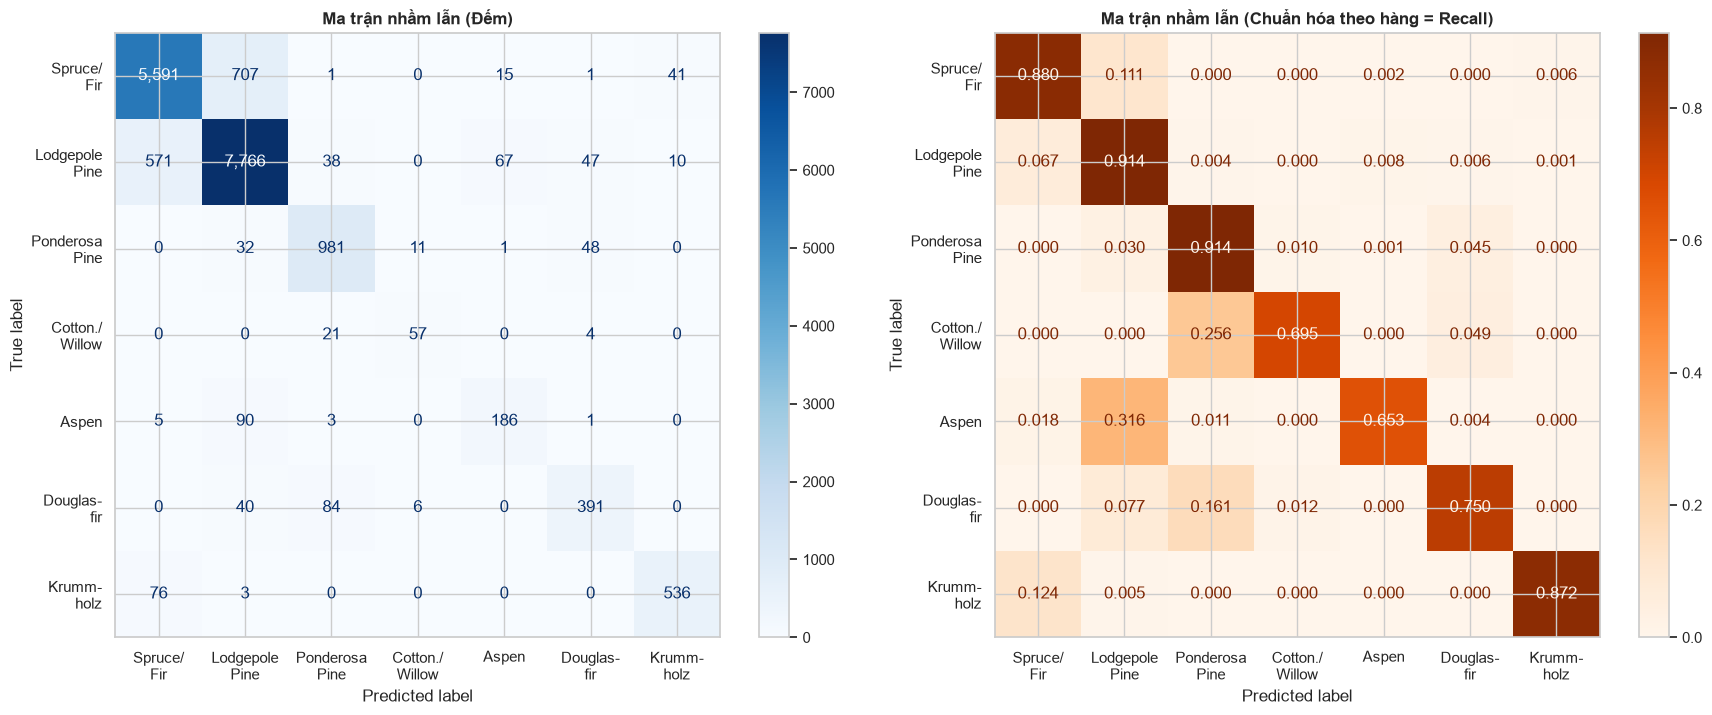


--- Phân tích lỗi chính ---
  Lớp 1 (Spruce/Fir): Recall=0.880, Lỗi chính → Lớp 2 (Lodgepole Pine): 707 mẫu
  Lớp 2 (Lodgepole Pine): Recall=0.914, Lỗi chính → Lớp 1 (Spruce/Fir): 571 mẫu
  Lớp 3 (Ponderosa Pine): Recall=0.914, Lỗi chính → Lớp 6 (Douglas-fir): 48 mẫu
  Lớp 4 (Cottonwood/Willow): Recall=0.695, Lỗi chính → Lớp 3 (Ponderosa Pine): 21 mẫu
  Lớp 5 (Aspen): Recall=0.653, Lỗi chính → Lớp 2 (Lodgepole Pine): 90 mẫu
  Lớp 6 (Douglas-fir): Recall=0.750, Lỗi chính → Lớp 3 (Ponderosa Pine): 84 mẫu
  Lớp 7 (Krummholz): Recall=0.872, Lỗi chính → Lớp 1 (Spruce/Fir): 76 mẫu


In [22]:
# === CONFUSION MATRIX ===
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Ma trận đếm
cm = confusion_matrix(y_test, y_pred_test, labels=range(1, 8))
short_names = ['Spruce/\nFir', 'Lodgepole\nPine', 'Ponderosa\nPine',
               'Cotton./\nWillow', 'Aspen', 'Douglas-\nfir', 'Krumm-\nholz']

disp1 = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=short_names)
disp1.plot(ax=axes[0], cmap='Blues', values_format=',')
axes[0].set_title('Ma trận nhầm lẫn (Đếm)', fontweight='bold')

# Ma trận tỷ lệ (chuẩn hóa theo hàng = Recall)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
disp2 = ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=short_names)
disp2.plot(ax=axes[1], cmap='Oranges', values_format='.3f')
axes[1].set_title('Ma trận nhầm lẫn (Chuẩn hóa theo hàng = Recall)', fontweight='bold')

plt.tight_layout()
plt.savefig(FIG_DIR / 'eval_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

# --- Phân tích lỗi chính ---
print("\n--- Phân tích lỗi chính ---")
for i in range(7):
    total = cm[i].sum()
    correct = cm[i, i]
    if total > 0:
        errors = [(cm[i, j], j) for j in range(7) if j != i and cm[i, j] > 0]
        errors.sort(reverse=True)
        if errors:
            top_err = errors[0]
            print(f"  Lớp {i+1} ({CLASS_NAMES[i+1]}): Recall={correct/total:.3f}, "
                  f"Lỗi chính → Lớp {top_err[1]+1} ({CLASS_NAMES[top_err[1]+1]}): {top_err[0]} mẫu")

## 5.2. Đánh giá trên Hold-out lớn (≈493.860 mẫu)

In [23]:
# === ĐÁNH GIÁ TRÊN HOLD-OUT LỚN ===
print("=" * 80)
print("  ĐÁNH GIÁ TRÊN HOLD-OUT LỚN (~493.860 mẫu)")
print("=" * 80)

# Biến đổi đặc trưng cho hold-out
X_holdout_best = engineer_features(X_holdout, soil_representation=best_soil_repr)

rf_final = res_final['model']
t_start = time.time()
y_pred_holdout = rf_final.predict(X_holdout_best)
t_pred = time.time() - t_start

# Chỉ số
acc_ho = accuracy_score(y_holdout, y_pred_holdout)
macro_f1_ho = f1_score(y_holdout, y_pred_holdout, average='macro')
weighted_f1_ho = f1_score(y_holdout, y_pred_holdout, average='weighted')

print(f"  Accuracy:     {acc_ho:.4f}")
print(f"  Macro F1:     {macro_f1_ho:.4f}")
print(f"  Weighted F1:  {weighted_f1_ho:.4f}")
print(f"  Thời gian dự đoán: {t_pred:.1f}s cho {len(y_holdout):,} mẫu")

# Recall lớp 4 trên hold-out (mẫu lớn hơn, khoảng tin cậy hẹp hơn)
recall_ho = recall_score(y_holdout, y_pred_holdout, average=None, labels=range(1, 8), zero_division=0)
n_c4_ho = (y_holdout == 4).sum()
p_hat = recall_ho[3]
z = 1.96
denom = 1 + z**2 / n_c4_ho
center = (p_hat + z**2 / (2 * n_c4_ho)) / denom
margin = z * np.sqrt((p_hat * (1 - p_hat) + z**2 / (4 * n_c4_ho)) / n_c4_ho) / denom
ci_lo, ci_hi = max(0, center - margin), min(1, center + margin)

print(f"\n  Recall lớp 4 (Hold-out): {p_hat:.4f}  [KTC 95%: {ci_lo:.4f} – {ci_hi:.4f}] (n={n_c4_ho:,})")
print(f"  → Khoảng tin cậy hẹp hơn Test vì n lớn hơn nhiều")

# Classification report on hold-out
print(f"\n--- Classification Report — Hold-out lớn ---")
print(classification_report(y_holdout, y_pred_holdout, target_names=target_names, digits=4))

  ĐÁNH GIÁ TRÊN HOLD-OUT LỚN (~493.860 mẫu)
  Accuracy:     0.8901
  Macro F1:     0.8320
  Weighted F1:  0.8899
  Thời gian dự đoán: 4.8s cho 493,861 mẫu

  Recall lớp 4 (Hold-out): 0.7452  [KTC 95%: 0.7271 – 0.7624] (n=2,335)
  → Khoảng tin cậy hẹp hơn Test vì n lớn hơn nhiều

--- Classification Report — Hold-out lớn ---
                           precision    recall  f1-score   support

       Lớp 1 (Spruce/Fir)     0.8988    0.8763    0.8874    180064
   Lớp 2 (Lodgepole Pine)     0.8971    0.9149    0.9059    240806
   Lớp 3 (Ponderosa Pine)     0.8644    0.9122    0.8877     30391
Lớp 4 (Cottonwood/Willow)     0.8215    0.7452    0.7815      2335
            Lớp 5 (Aspen)     0.6822    0.6710    0.6765      8069
      Lớp 6 (Douglas-fir)     0.8086    0.7571    0.7820     14762
        Lớp 7 (Krummholz)     0.9211    0.8857    0.9031     17434

                 accuracy                         0.8901    493861
                macro avg     0.8420    0.8232    0.8320    493861
   

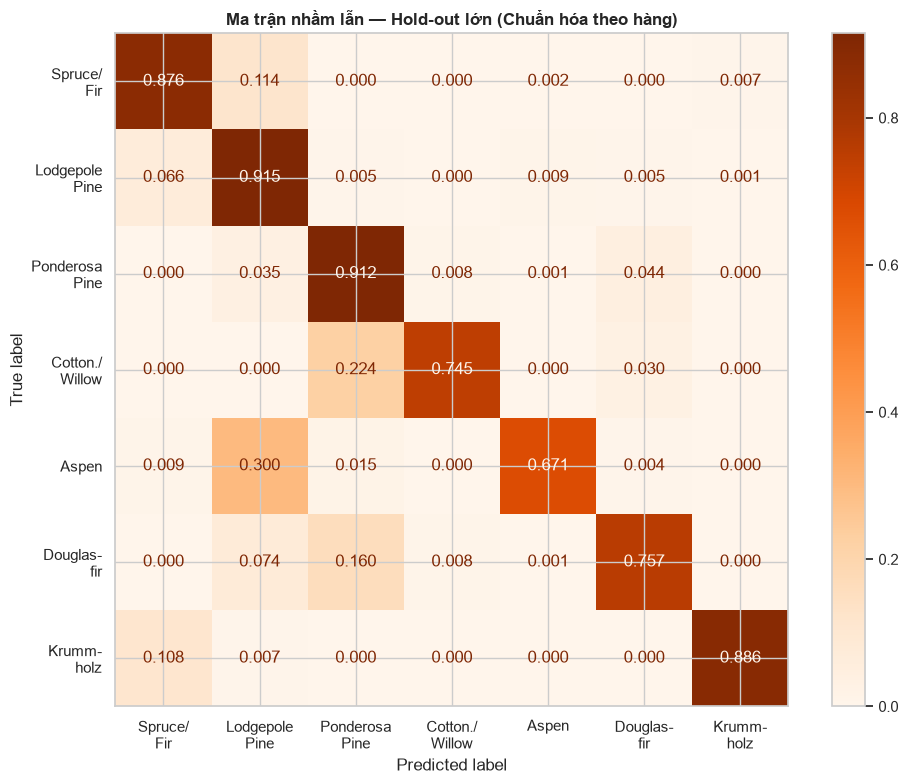

In [24]:
# === CONFUSION MATRIX — HOLD-OUT ===
fig, ax = plt.subplots(figsize=(10, 8))
cm_ho = confusion_matrix(y_holdout, y_pred_holdout, labels=range(1, 8))
cm_ho_norm = cm_ho.astype(float) / cm_ho.sum(axis=1, keepdims=True)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_ho_norm, display_labels=short_names)
disp.plot(ax=ax, cmap='Oranges', values_format='.3f')
ax.set_title('Ma trận nhầm lẫn — Hold-out lớn (Chuẩn hóa theo hàng)', fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / 'eval_confusion_holdout.png', dpi=150, bbox_inches='tight')
plt.show()

## 5.3. Tầm quan trọng đặc trưng: Gini Importance & Permutation Importance

Đang tính Permutation Importance trên tập Test (có thể mất 1-2 phút)...


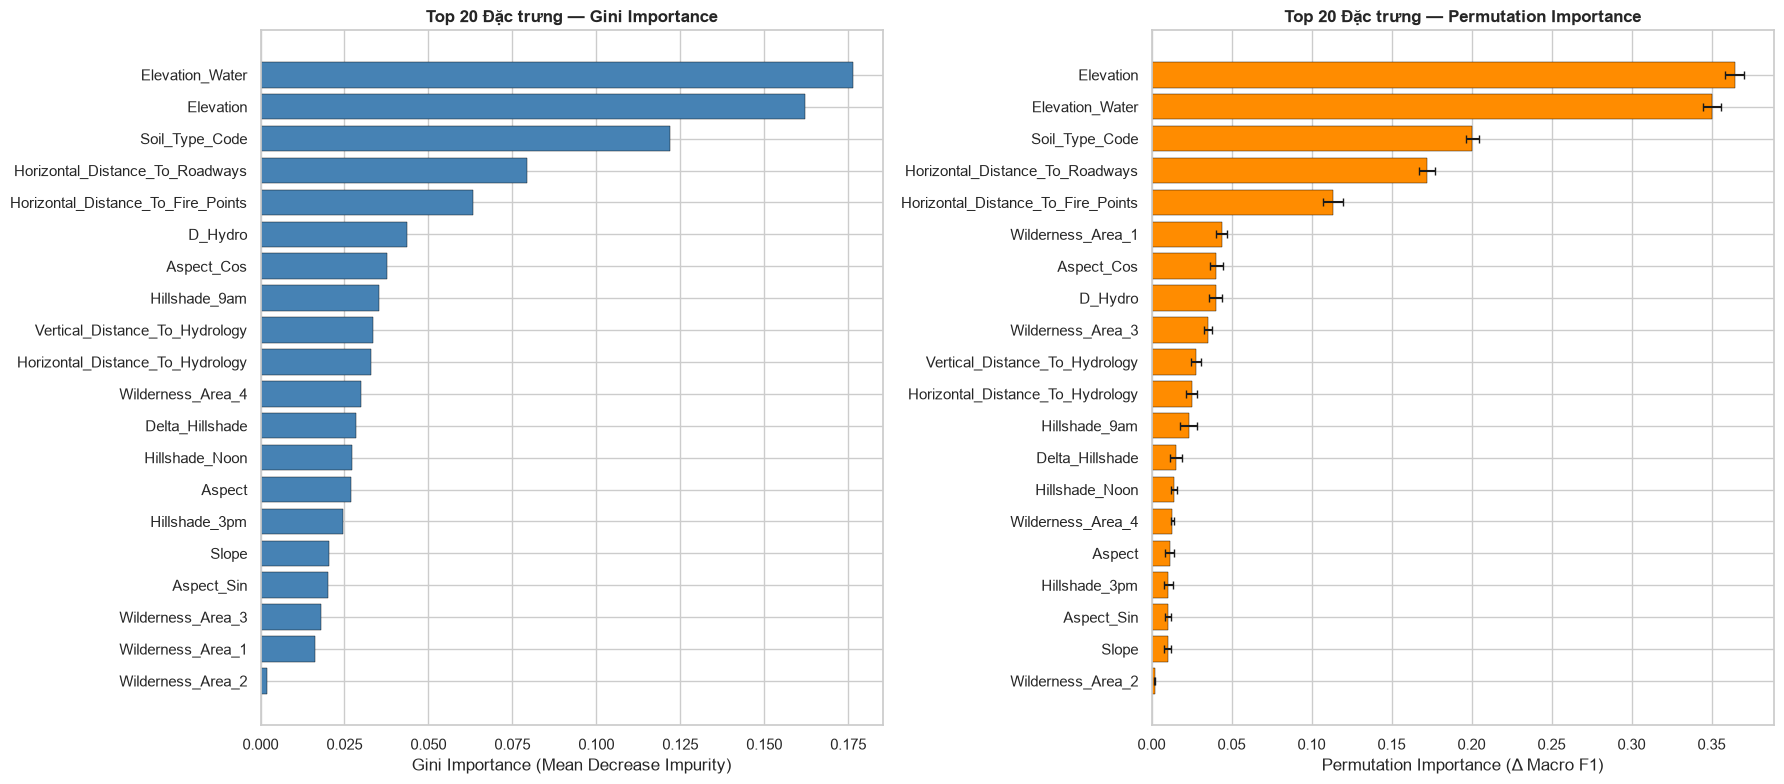


--- Top 10 đặc trưng (Permutation Importance) ---
   1. Elevation                            0.3645 ± 0.0060
   2. Elevation_Water                      0.3505 ± 0.0056
   3. Soil_Type_Code                       0.2004 ± 0.0040
   4. Horizontal_Distance_To_Roadways      0.1720 ± 0.0050
   5. Horizontal_Distance_To_Fire_Points   0.1136 ± 0.0063
   6. Wilderness_Area_1                    0.0438 ± 0.0032
   7. Aspect_Cos                           0.0405 ± 0.0041
   8. D_Hydro                              0.0401 ± 0.0043
   9. Wilderness_Area_3                    0.0352 ± 0.0026
  10. Vertical_Distance_To_Hydrology       0.0277 ± 0.0032


In [25]:
# === GINI IMPORTANCE (Mean Decrease Impurity) ===
feature_names = X_train_best.columns.tolist()
gini_imp = pd.Series(rf_final.feature_importances_, index=feature_names).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Top 20 Gini Importance
top_n = 20
gini_top = gini_imp.head(top_n)
axes[0].barh(range(top_n), gini_top.values, color='steelblue', edgecolor='black', linewidth=0.3)
axes[0].set_yticks(range(top_n))
axes[0].set_yticklabels(gini_top.index)
axes[0].invert_yaxis()
axes[0].set_xlabel('Gini Importance (Mean Decrease Impurity)')
axes[0].set_title(f'Top {top_n} Đặc trưng — Gini Importance', fontweight='bold')

# === PERMUTATION IMPORTANCE (trên Test) ===
print("Đang tính Permutation Importance trên tập Test (có thể mất 1-2 phút)...")
perm_imp = permutation_importance(
    rf_final, X_test_best, y_test,
    n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1,
    scoring='f1_macro'
)

perm_imp_series = pd.Series(perm_imp.importances_mean, index=feature_names).sort_values(ascending=False)
perm_imp_std = pd.Series(perm_imp.importances_std, index=feature_names)

perm_top = perm_imp_series.head(top_n)
perm_std_top = perm_imp_std[perm_top.index]

axes[1].barh(range(top_n), perm_top.values, xerr=perm_std_top.values,
             color='darkorange', edgecolor='black', linewidth=0.3, capsize=3)
axes[1].set_yticks(range(top_n))
axes[1].set_yticklabels(perm_top.index)
axes[1].invert_yaxis()
axes[1].set_xlabel('Permutation Importance (Δ Macro F1)')
axes[1].set_title(f'Top {top_n} Đặc trưng — Permutation Importance', fontweight='bold')

plt.tight_layout()
plt.savefig(FIG_DIR / 'eval_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n--- Top 10 đặc trưng (Permutation Importance) ---")
for i, (feat, imp) in enumerate(perm_top.head(10).items()):
    std = perm_imp_std[feat]
    print(f"  {i+1:>2}. {feat:<35s}  {imp:.4f} ± {std:.4f}")

## 5.4. So sánh đặc trưng sinh thái mới vs đặc trưng gốc

In [26]:
# === PHÂN TÍCH ĐẶC TRƯNG SINH THÁI MỚI ===
eco_features_added = ['D_Hydro', 'Elevation_Water', 'Aspect_Cos', 'Aspect_Sin', 'Delta_Hillshade']
eco_in_model = [f for f in eco_features_added if f in feature_names]

print("=" * 70)
print("  VAI TRÒ CỦA CÁC ĐẶC TRƯNG SINH THÁI MỚI")
print("=" * 70)
print(f"{'Đặc trưng':<25s} {'Gini Imp':>12} {'Perm Imp':>12} {'Perm Rank':>12}")
print("-" * 70)

perm_ranks = perm_imp_series.rank(ascending=False)
gini_ranks = gini_imp.rank(ascending=False)

for feat in eco_in_model:
    gi = gini_imp.get(feat, 0)
    pi = perm_imp_series.get(feat, 0)
    pr = perm_ranks.get(feat, -1)
    print(f"  {feat:<23s} {gi:>12.4f} {pi:>12.4f} {pr:>12.0f}/{len(feature_names)}")

  VAI TRÒ CỦA CÁC ĐẶC TRƯNG SINH THÁI MỚI
Đặc trưng                     Gini Imp     Perm Imp    Perm Rank
----------------------------------------------------------------------
  D_Hydro                       0.0435       0.0401            8/20
  Elevation_Water               0.1765       0.3505            2/20
  Aspect_Cos                    0.0378       0.0405            7/20
  Aspect_Sin                    0.0200       0.0104           18/20
  Delta_Hillshade               0.0286       0.0155           13/20


## 5.5. Bảng tổng kết toàn bộ thí nghiệm Ablation

In [27]:
# === BẢNG TỔNG KẾT ABLATION ===
print("=" * 110)
print("  BẢNG TỔNG KẾT TOÀN BỘ THÍ NGHIỆM ABLATION")
print("=" * 110)
print(f"{'#':<4} {'Cấu hình':<50s} {'Accuracy':>10} {'Macro F1':>10} {'Recall C4':>12} {'Prec. C4':>10} {'Time(s)':>8}")
print("-" * 110)
for i, res in enumerate(ablation_results):
    ci = res.get('recall_c4_ci', (0, 0))
    rc4_str = f"{res['recall_class4']:.4f}"
    print(f"{i+1:<4} {res['label']:<50s} {res['accuracy']:>10.4f} {res['macro_f1']:>10.4f} "
          f"{rc4_str:>12s} {res['precision_class4']:>10.4f} {res['train_time_s']:>8.1f}")
print("-" * 110)

# Lưu kết quả ra CSV
results_df = pd.DataFrame([{
    'config': r['label'],
    'accuracy': r['accuracy'],
    'macro_f1': r['macro_f1'],
    'weighted_f1': r['weighted_f1'],
    'recall_class4': r['recall_class4'],
    'recall_c4_ci_low': r['recall_c4_ci'][0],
    'recall_c4_ci_high': r['recall_c4_ci'][1],
    'precision_class4': r['precision_class4'],
    'train_time_s': r['train_time_s'],
    'peak_ram_mb': r['peak_ram_mb'],
    'n_class4_test': r['n_class4_test'],
} for r in ablation_results])

CSV_PATH = TABLE_DIR / 'ablation_results.csv'
results_df.to_csv(CSV_PATH, index=False, encoding='utf-8-sig')
print(f"\n✓ Kết quả đã lưu tại: {CSV_PATH}")

  BẢNG TỔNG KẾT TOÀN BỘ THÍ NGHIỆM ABLATION
#    Cấu hình                                             Accuracy   Macro F1    Recall C4   Prec. C4  Time(s)
--------------------------------------------------------------------------------------------------------------
1    E0: Baseline (class_weight=None)                       0.8707     0.7908       0.7317     0.8696      3.5
2    E1a: class_weight='balanced'                           0.8473     0.7977       0.7805     0.7805      3.1
3    E1b: class_weight='balanced_subsample'                 0.8713     0.8083       0.7073     0.7632      4.0
4    E2-Full: Tất cả đặc trưng sinh thái                    0.8713     0.8083       0.7073     0.7632      4.0
5    E2-Drop: Bỏ D_Hydro                                    0.8703     0.8113       0.7195     0.8082      3.9
6    E2-Drop: Bỏ Elevation_Water                            0.8657     0.7970       0.6707     0.7746      4.0
7    E2-Drop: Bỏ Aspect_Trig                                0.8766  

## 5.6. Tổng kết Bước 1–5

> **Lưu ý**: Tất cả số liệu trong notebook này là **kết quả thực nghiệm** chạy trên máy cục bộ. 
> Các **[KỲ VỌNG]** và **[GIẢ THUYẾT]** trong tài liệu `docs/` cần được cập nhật bằng các số đo thực tế này.
> 
> **Bước tiếp theo**: Bước 5B (cải thiện mô hình trước khi trích xuất), sau đó:
> - **Bước 6**: Trích xuất luật sinh thái rừng (Cây đại diện → DFS → If-Then Rules)
> - **Bước 7**: Xây dựng hàm tương tác thực địa `du_doan_kieu_rung()`
> - **Bước 8**: Đóng gói Notebook & Báo cáo tổng kết

---
# BƯỚC 5B: CẢI THIỆN MÔ HÌNH TRƯỚC KHI TRÍCH XUẤT CÂY ĐẠI DIỆN
> **Mục tiêu**: Kiểm tra ba nguồn cải thiện còn để ngỏ sau Bước 4–5 trước khi chốt mô hình chủ (teacher) cho Bước 6:
> 1. **E4 — Quy mô dữ liệu huấn luyện**: mô hình Bước 4.7 chỉ học trên 69.720 mẫu (12% dữ liệu).
> 2. **E2b / E3-D — Đặc trưng**: tổ hợp khoảng cách (đã có trong kế hoạch E2 nhưng chưa chạy), biểu diễn đất (D) Code + Zones, và phương án bỏ các đặc trưng đóng góp thấp.
> 3. **E5 mở rộng — Siêu tham số**: `max_features`, `criterion`, `min_samples_leaf`, `class_weight` (chưa được quét ở 4.6).
>
> **Tham chiếu**: [KE_HOACH_THI_NGHIEM.md](../docs/02_ke_hoach_va_kien_truc/KE_HOACH_THI_NGHIEM.md) — mục 2.2 (lặp 3 seed), mục 5 (quy tắc ra quyết định).

### Thiết kế phân chia lại dữ liệu

| Tập | Nguồn | Quy mô | Vai trò |
| :--- | :--- | :---: | :--- |
| **D_final** | 20% toàn bộ, rút phân tầng **chỉ từ hold-out cũ** | ≈ 116.202 (lớp 4 ≈ 549) | Đánh giá **một lần** sau khi chốt cấu hình; đo Fidelity cây đại diện ở Bước 6 |
| **D_val** | 20% toàn bộ, từ phần còn lại | ≈ 116.202 (lớp 4 ≈ 549) | So sánh cấu hình trong E4, E2b, E5. Sau khi chốt: **bể truy vấn** cho cây đại diện |
| **D_pool** | 60% toàn bộ còn lại | ≈ 348.608 | Bể huấn luyện; E4 lấy 5% → 100% |

**Lý do thiết kế**:
- D_final chỉ rút từ hold-out cũ, nên không chứa mẫu nào của Test cũ (tập đã dùng để chọn cấu hình ở E1–E3).
- D_val có ≈ 549 mẫu lớp 4, gấp khoảng 6,7 lần Test cũ (82 mẫu). Khoảng tin cậy Wilson cho Recall lớp 4 vì vậy hẹp hơn khi so sánh cấu hình.
- Mọi quyết định trong 5B dùng trung bình ± độ lệch chuẩn qua 3 seed. Chênh lệch nhỏ hơn độ lệch chuẩn được coi là không khác biệt có ý nghĩa; khi đó chọn cấu hình đơn giản hơn (ít đặc trưng hơn, ít nút hơn).

**Hạn chế đã biết**:
- Độ lệch chuẩn qua seed chỉ phản ánh biến thiên do lấy mẫu con và do RF, **không** phản ánh biến thiên do chia D_val (D_val cố định).
- Dữ liệu UCI không có toạ độ: các ô lưới 30 m liền kề có thể rơi vào cả D_pool lẫn D_final, nên các chỉ số dưới đây có khả năng **ước lượng cao hơn** năng lực tổng quát hoá sang vùng mới (tự tương quan không gian). Kiểm tra thay thế E6 (leave-one-wilderness-out) chưa nằm trong phạm vi 5B.
- E1–E3 được chọn trên mẫu 15%; lựa chọn `class_weight` được kiểm tra lại trong E5, còn lựa chọn biểu diễn đất được kiểm tra lại một phần qua E3-D.

## 5B.1. Phân chia lại dữ liệu & giải phóng bộ nhớ

In [28]:
import gc
import psutil

STAGE_B_SEEDS = [42, 7, 2024]          # 3 seed theo mục 2.2 kế hoạch thí nghiệm
SOIL_B = best_soil_repr                # biểu diễn đất đã chọn ở E3
CW_B = best_cw                         # class_weight đã chọn ở E1 (kiểm tra lại ở E5)
BYTES_PER_NODE = 64 + 7 * 8            # ước lượng: struct Node của sklearn + mảng value (7 lớp, float64)


def wilson_ci(k, n, z=1.96):
    """Khoảng tin cậy Wilson 95% cho tỷ lệ k/n."""
    if n == 0:
        return (0.0, 0.0)
    p = k / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    margin = z * np.sqrt((p * (1 - p) + z**2 / (4 * n)) / n) / denom
    return (max(0.0, center - margin), min(1.0, center + margin))


def eval_preds(y_true, y_pred):
    """Các chỉ số dùng chung trong 5B."""
    y_true = np.asarray(y_true)
    rec = recall_score(y_true, y_pred, average=None, labels=range(1, 8), zero_division=0)
    prec = precision_score(y_true, y_pred, average=None, labels=range(1, 8), zero_division=0)
    n4 = int((y_true == 4).sum())
    k4 = int(((y_true == 4) & (np.asarray(y_pred) == 4)).sum())
    out = {
        'accuracy': accuracy_score(y_true, y_pred),
        'macro_f1': f1_score(y_true, y_pred, average='macro'),
        'precision_c4': prec[3],
        'recall_c4_ci': wilson_ci(k4, n4),
    }
    for c in range(1, 8):
        out[f'recall_c{c}'] = rec[c - 1]
    return out


def n_nodes(rf):
    return int(sum(e.tree_.node_count for e in rf.estimators_))


def rss_gb():
    return psutil.Process().memory_info().rss / 2**30


# --- 1. D_final: 20% toàn bộ, rút CHỈ từ hold-out cũ ---
N_EVAL = int(round(0.20 * len(df_raw)))
X_ho_rest, X_final_raw, y_ho_rest, y_final = train_test_split(
    X_holdout, y_holdout, test_size=N_EVAL, stratify=y_holdout, random_state=RANDOM_STATE)

# --- 2. D_val và D_pool từ phần còn lại (mẫu 15% cũ + phần hold-out còn lại) ---
X_dev_raw = pd.concat([X_sample, X_ho_rest])
y_dev = pd.concat([y_sample, y_ho_rest])
X_pool_raw, X_val_raw, y_pool, y_val = train_test_split(
    X_dev_raw, y_dev, test_size=N_EVAL, stratify=y_dev, random_state=RANDOM_STATE)

# --- 3. Kiểm tra tính rời nhau ---
idx_final, idx_val, idx_pool = set(X_final_raw.index), set(X_val_raw.index), set(X_pool_raw.index)
assert idx_final.isdisjoint(idx_val) and idx_final.isdisjoint(idx_pool) and idx_val.isdisjoint(idx_pool)
assert idx_final.isdisjoint(X_test_raw.index) and idx_final.isdisjoint(X_train_raw.index)
assert len(idx_final) + len(idx_val) + len(idx_pool) == len(df_raw)
print("✓ D_final, D_val, D_pool rời nhau và phủ đủ 581.012 dòng; D_final không chứa mẫu Train/Test cũ.")

split_tbl = pd.DataFrame({
    'D_final': y_final.value_counts().sort_index(),
    'D_val': y_val.value_counts().sort_index(),
    'D_pool': y_pool.value_counts().sort_index(),
})
split_tbl.index = [f"Lớp {i} ({CLASS_NAMES[i]})" for i in split_tbl.index]
split_tbl.loc['Tổng'] = split_tbl.sum()
display(split_tbl)

# --- 4. Dự đoán của mô hình Bước 4.7 trên D_final: lưu lại để so sánh ở 5B.6 (chưa công bố) ---
y_final_pred_old = rf_final.predict(engineer_features(X_final_raw, soil_representation=SOIL_B))

# --- 5. Giải phóng các mô hình cũ trong bộ nhớ ---
print(f"RAM tiến trình trước khi giải phóng: {rss_gb():.2f} GB")
for r in ablation_results:
    r['model'] = None
res_final['model'] = None
for _name in ['rf_final', 'X_holdout_fe', 'X_holdout_best', 'perm_imp', 'rf']:
    globals().pop(_name, None)
gc.collect()
print(f"RAM tiến trình sau khi giải phóng:  {rss_gb():.2f} GB")
print(f"RAM hệ thống còn trống:            {psutil.virtual_memory().available / 2**30:.2f} GB")

✓ D_final, D_val, D_pool rời nhau và phủ đủ 581.012 dòng; D_final không chứa mẫu Train/Test cũ.


,D_final,D_val,D_pool
Lớp 1 (Spruce/Fir),42368,42368,127104
Lớp 2 (Lodgepole Pine),56660,56660,169981
Lớp 3 (Ponderosa Pine),7151,7151,21452
Lớp 4 (Cottonwood/Willow),549,550,1648
Lớp 5 (Aspen),1899,1898,5696
Lớp 6 (Douglas-fir),3473,3473,10421
Lớp 7 (Krummholz),4102,4102,12306
Tổng,116202,116202,348608


RAM tiến trình trước khi giải phóng: 0.80 GB
RAM tiến trình sau khi giải phóng:  0.40 GB
RAM hệ thống còn trống:            7.23 GB


## 5B.2. Thí nghiệm E4: Đường cong học theo quy mô dữ liệu huấn luyện
> Huấn luyện RF (`n_estimators=100`, `class_weight` từ E1) trên 5% / 10% / 25% / 50% / 75% / 100% của D_pool với `max_depth` ∈ {20, None}, mỗi mức 3 seed; đánh giá trên D_val cố định.
>
> **Quy tắc chọn**: với mỗi `max_depth`, lấy mức dữ liệu **nhỏ nhất** có Macro-F1 trung bình không thấp hơn (Macro-F1 tốt nhất − 1 độ lệch chuẩn của cấu hình tốt nhất). Số nút (node count) được ghi lại vì kích thước rừng ảnh hưởng tới RAM và chi phí truy vấn ở Bước 6.

In [29]:
X_pool = engineer_features(X_pool_raw, soil_representation=SOIL_B).astype(np.float32)
X_val = engineer_features(X_val_raw, soil_representation=SOIL_B).astype(np.float32)

E4_FRACS = [0.05, 0.10, 0.25, 0.50, 0.75, 1.00]
E4_DEPTHS = [20, None]
E4_N_EST = 100


def pool_subset_idx(frac, seed):
    """Chỉ số con phân tầng của D_pool theo tỷ lệ frac."""
    if frac >= 1.0:
        return np.arange(len(y_pool))
    idx, _ = train_test_split(np.arange(len(y_pool)), train_size=frac,
                              stratify=y_pool, random_state=seed)
    return np.sort(idx)


e4_rows = []
t_e4 = time.time()
for frac in E4_FRACS:
    for seed in STAGE_B_SEEDS:
        idx = pool_subset_idx(frac, seed)
        for depth in E4_DEPTHS:
            rf_tmp = RandomForestClassifier(n_estimators=E4_N_EST, max_depth=depth, class_weight=CW_B,
                                            random_state=seed, n_jobs=-1)
            t0 = time.time()
            rf_tmp.fit(X_pool.iloc[idx], y_pool.iloc[idx])
            t_fit = time.time() - t0
            m = eval_preds(y_val, rf_tmp.predict(X_val))
            e4_rows.append({'frac': frac, 'n_train': len(idx), 'max_depth': str(depth), 'seed': seed,
                            **{k: v for k, v in m.items() if k != 'recall_c4_ci'},
                            'fit_s': t_fit, 'nodes': n_nodes(rf_tmp), 'rss_gb': rss_gb()})
            del rf_tmp
            gc.collect()
    print(f"  xong frac={frac:.2f} ({time.time() - t_e4:.0f}s)")

e4_df = pd.DataFrame(e4_rows)
e4_df.to_csv(TABLE_DIR / 'e4_learning_curve.csv', index=False, encoding='utf-8-sig')

e4_sum = (e4_df.groupby(['max_depth', 'frac', 'n_train'])
          .agg(acc_mean=('accuracy', 'mean'), acc_sd=('accuracy', 'std'),
               f1_mean=('macro_f1', 'mean'), f1_sd=('macro_f1', 'std'),
               rc4_mean=('recall_c4', 'mean'), rc4_sd=('recall_c4', 'std'),
               rc5_mean=('recall_c5', 'mean'), rc6_mean=('recall_c6', 'mean'),
               fit_s=('fit_s', 'mean'), nodes=('nodes', 'mean'))
          .reset_index())
print("\n=== E4: TRUNG BÌNH ± ĐỘ LỆCH CHUẨN QUA 3 SEED (đánh giá trên D_val) ===")
display(e4_sum)

  xong frac=0.05 (8s)
  xong frac=0.10 (18s)
  xong frac=0.25 (36s)
  xong frac=0.50 (77s)
  xong frac=0.75 (145s)
  xong frac=1.00 (247s)

=== E4: TRUNG BÌNH ± ĐỘ LỆCH CHUẨN QUA 3 SEED (đánh giá trên D_val) ===


,max_depth,frac,n_train,acc_mean,acc_sd,f1_mean,f1_sd,rc4_mean,rc4_sd,rc5_mean,rc6_mean,fit_s,nodes
0,20,0.0500,17430,0.8290,0.0022,0.7303,0.0056,0.5836,0.0637,0.3721,0.5414,0.6760,512425.3333
1,20,0.1000,34860,0.8601,0.0015,0.7858,0.0005,0.6697,0.0336,0.5272,0.6552,1.0009,864208.6667
2,20,0.2500,87152,0.8957,0.0015,0.8391,0.0017,0.7436,0.0164,0.7211,0.7843,2.2219,1593710.6667
3,20,0.5000,174304,0.9178,0.0004,0.8707,0.0027,0.7945,0.0018,0.8214,0.8631,5.9677,2386706.0000
4,20,0.7500,261456,0.9270,0.0012,0.8831,0.0022,0.8176,0.0052,0.8671,0.8946,10.5264,2981834.6667
5,20,1.0000,348608,0.9325,0.0003,0.8904,0.0009,0.8273,0.0018,0.8995,0.9124,15.8595,3457326.0000
6,None,0.0500,17430,0.8314,0.0013,0.7169,0.0067,0.5776,0.0440,0.2710,0.5039,0.6890,580107.3333
7,None,0.1000,34860,0.8671,0.0009,0.7793,0.0003,0.6703,0.0212,0.3908,0.6146,1.0526,1045558.0000
8,None,0.2500,87152,0.9098,0.0007,0.8483,0.0015,0.7339,0.0182,0.5646,0.7554,2.3819,2197594.0000
9,None,0.5000,174304,0.9360,0.0002,0.8896,0.0019,0.7782,0.0109,0.6872,0.8290,6.2281,3694067.3333


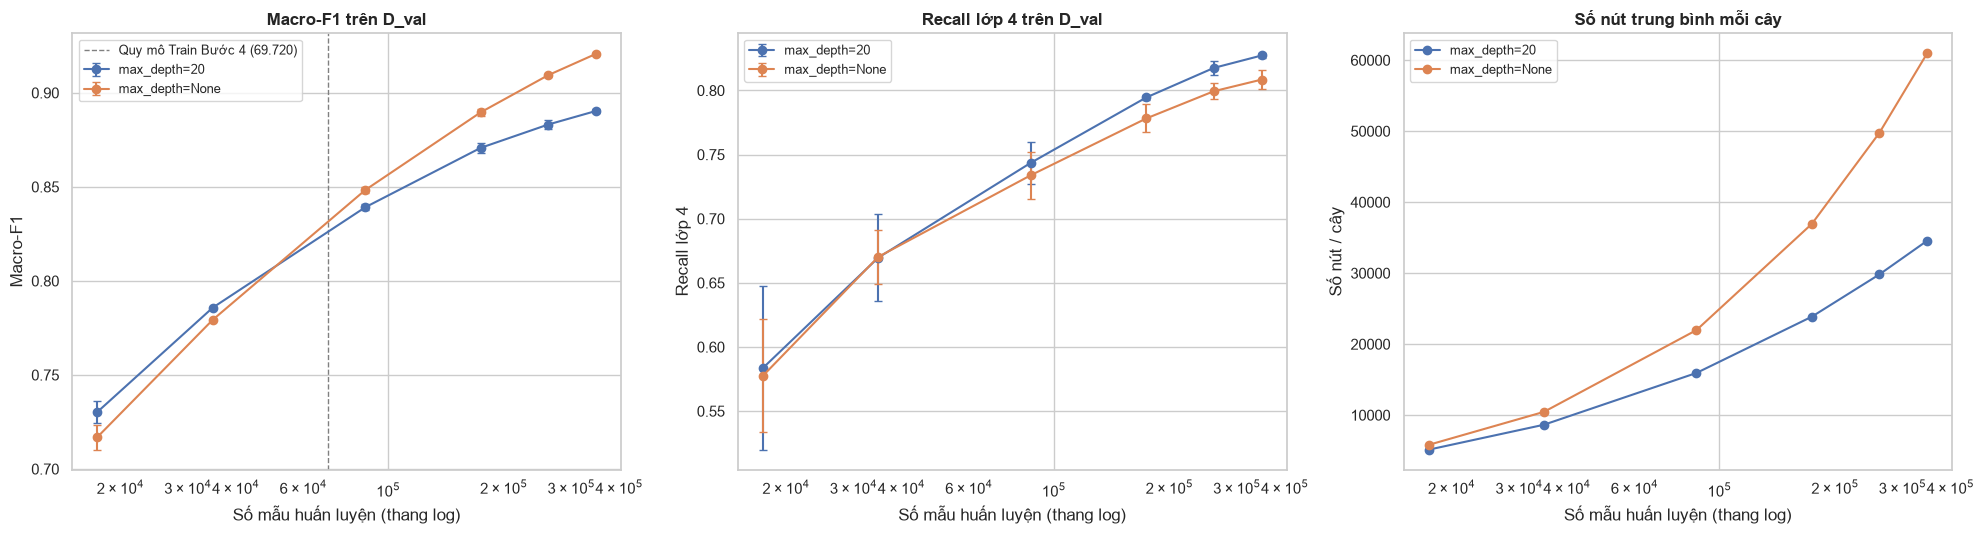

=== Lựa chọn theo quy tắc: mức nhỏ nhất có F1 ≥ (F1 tốt nhất − 1 SD) ===
  max_depth=20   : tốt nhất frac=1.00 (F1=0.8904 ± 0.0009); ngưỡng 0.8894 → chọn frac=1.00 (n=348,608, F1=0.8904)
  max_depth=None : tốt nhất frac=1.00 (F1=0.9207 ± 0.0004); ngưỡng 0.9204 → chọn frac=1.00 (n=348,608, F1=0.9207)

→ Quy mô dữ liệu được chọn: 100% D_pool (n=348,608); max_depth=None
  (Tham khảo: chênh lệch Macro-F1 so với max_depth=20 tại 25% D_pool ≈ quy mô 87K: +0.0816)


In [30]:
# === BIỂU ĐỒ ĐƯỜNG CONG HỌC ===
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for depth, grp in e4_sum.groupby('max_depth'):
    lbl = f"max_depth={depth}"
    axes[0].errorbar(grp['n_train'], grp['f1_mean'], yerr=grp['f1_sd'], marker='o', capsize=3, label=lbl)
    axes[1].errorbar(grp['n_train'], grp['rc4_mean'], yerr=grp['rc4_sd'], marker='o', capsize=3, label=lbl)
    axes[2].plot(grp['n_train'], grp['nodes'] / E4_N_EST, marker='o', label=lbl)
axes[0].axvline(len(X_train_raw), color='gray', ls='--', lw=1, label='Quy mô Train Bước 4 (69.720)')
for ax, title, ylab in zip(axes,
                           ['Macro-F1 trên D_val', 'Recall lớp 4 trên D_val', 'Số nút trung bình mỗi cây'],
                           ['Macro-F1', 'Recall lớp 4', 'Số nút / cây']):
    ax.set_xscale('log')
    ax.set_xlabel('Số mẫu huấn luyện (thang log)')
    ax.set_ylabel(ylab)
    ax.set_title(title, fontweight='bold')
    ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(FIG_DIR / 'e4_learning_curve.png', dpi=150, bbox_inches='tight')
plt.show()

# === QUY TẮC CHỌN QUY MÔ DỮ LIỆU ===
print("=== Lựa chọn theo quy tắc: mức nhỏ nhất có F1 ≥ (F1 tốt nhất − 1 SD) ===")
e4_choice = {}
for depth, grp in e4_sum.groupby('max_depth'):
    best = grp.loc[grp['f1_mean'].idxmax()]
    thr = best['f1_mean'] - best['f1_sd']
    chosen = grp[grp['f1_mean'] >= thr].sort_values('frac').iloc[0]
    e4_choice[depth] = chosen
    print(f"  max_depth={depth:<5}: tốt nhất frac={best['frac']:.2f} (F1={best['f1_mean']:.4f} ± {best['f1_sd']:.4f}); "
          f"ngưỡng {thr:.4f} → chọn frac={chosen['frac']:.2f} (n={int(chosen['n_train']):,}, F1={chosen['f1_mean']:.4f})")

# Chọn max_depth có F1 trung bình cao hơn tại mức dữ liệu đã chọn của nó
best_depth_key = max(e4_choice, key=lambda d: e4_choice[d]['f1_mean'])
E4_FRAC = float(e4_choice[best_depth_key]['frac'])
E4_DEPTH = None if best_depth_key == 'None' else int(best_depth_key)
idx_train_b = pool_subset_idx(E4_FRAC, RANDOM_STATE)
print(f"\n→ Quy mô dữ liệu được chọn: {E4_FRAC:.0%} D_pool (n={len(idx_train_b):,}); max_depth={E4_DEPTH}")
gain = e4_choice[best_depth_key]['f1_mean'] - e4_sum.query("max_depth=='20' and frac==0.25")['f1_mean'].iloc[0]
print(f"  (Tham khảo: chênh lệch Macro-F1 so với max_depth=20 tại 25% D_pool ≈ quy mô 87K: {gain:+.4f})")

## 5B.3. Thí nghiệm E2b / E3-D: Kiểm tra lại tập đặc trưng ở quy mô dữ liệu đã chọn
| Phương án | Mô tả | Cơ sở |
| :--- | :--- | :--- |
| **F0** | Tập đặc trưng hiện tại (Soil_Type_Code + 5 đặc trưng sinh thái) | Kết quả E2–E3 |
| **F1** | F0 − {`Aspect_Sin`, `Delta_Hillshade`} | Hai đặc trưng có Permutation Importance thấp nhất trong nhóm sinh thái (mục 5.4); kiểm tra phương án đơn giản hơn |
| **F2** | F0 + tổ hợp khoảng cách (tổng và \|hiệu\| của 3 khoảng cách ngang Hydrology / Roadways / Fire_Points, 6 cột) | Đã liệt kê trong E2 của kế hoạch nhưng chưa chạy. Đây là heuristic thực hành phổ biến trên bộ dữ liệu này, **chưa có cơ sở bình duyệt**; mức đóng góp `[CẦN ĐO]` |
| **F3** | F0 + `Soil_Climatic_Zone` + `Soil_Geologic_Zone` | Phương án (D) Code + Zones trong E3 của kế hoạch |
| **F4** | F2 + F3 | Kết hợp |

> **Quy tắc chọn**: trong các phương án có Macro-F1 trung bình ≥ (tốt nhất − 1 SD), chọn phương án có **ít cột nhất**. Lý do: mỗi cột mới đều có thể xuất hiện trong luật của cây đại diện, nên cột khó diễn giải sinh thái chỉ được giữ khi có cải thiện đo được.

In [31]:
DIST_COMBO_COLS = ['Hydro_Fire_Sum', 'Hydro_Fire_Diff', 'Hydro_Road_Sum',
                   'Hydro_Road_Diff', 'Fire_Road_Sum', 'Fire_Road_Diff']
ZONE_COLS = ['Soil_Climatic_Zone', 'Soil_Geologic_Zone']


def engineer_features_b(df, soil_representation=SOIL_B, variant='F0'):
    """Mở rộng engineer_features() cho các phương án F0–F4 của E2b/E3-D."""
    out = engineer_features(df, soil_representation=soil_representation)
    if variant == 'F1':
        out = out.drop(columns=['Aspect_Sin', 'Delta_Hillshade'])
    if variant in ('F2', 'F4'):
        Hh = df['Horizontal_Distance_To_Hydrology'].astype(np.float32)
        Hr = df['Horizontal_Distance_To_Roadways'].astype(np.float32)
        Hf = df['Horizontal_Distance_To_Fire_Points'].astype(np.float32)
        out['Hydro_Fire_Sum'], out['Hydro_Fire_Diff'] = Hh + Hf, (Hh - Hf).abs()
        out['Hydro_Road_Sum'], out['Hydro_Road_Diff'] = Hh + Hr, (Hh - Hr).abs()
        out['Fire_Road_Sum'], out['Fire_Road_Diff'] = Hf + Hr, (Hf - Hr).abs()
    if variant in ('F3', 'F4'):
        code_ = df[[f'Soil_Type_{i}' for i in range(1, 41)]].values.argmax(axis=1) + 1
        out['Soil_Climatic_Zone'] = np.array([SOIL_TO_CLIMATIC[c] for c in code_], dtype=np.uint8)
        out['Soil_Geologic_Zone'] = np.array([SOIL_TO_GEOLOGIC[c] for c in code_], dtype=np.uint8)
    return out.astype(np.float32)


FEATURE_VARIANTS = ['F0', 'F1', 'F2', 'F3', 'F4']
X_pool_tr_raw = X_pool_raw.iloc[idx_train_b]
y_pool_tr = y_pool.iloc[idx_train_b]

e2b_rows = []
for var in FEATURE_VARIANTS:
    Xtr_v = engineer_features_b(X_pool_tr_raw, variant=var)
    Xval_v = engineer_features_b(X_val_raw, variant=var)
    for seed in STAGE_B_SEEDS:
        rf_tmp = RandomForestClassifier(n_estimators=E4_N_EST, max_depth=E4_DEPTH, class_weight=CW_B,
                                        random_state=seed, n_jobs=-1)
        rf_tmp.fit(Xtr_v, y_pool_tr)
        m = eval_preds(y_val, rf_tmp.predict(Xval_v))
        e2b_rows.append({'variant': var, 'n_features': Xtr_v.shape[1], 'seed': seed,
                         **{k: v for k, v in m.items() if k != 'recall_c4_ci'}, 'nodes': n_nodes(rf_tmp)})
        del rf_tmp
        gc.collect()
    print(f"  xong {var} ({Xtr_v.shape[1]} cột)")
    del Xtr_v, Xval_v

e2b_df = pd.DataFrame(e2b_rows)
e2b_sum = (e2b_df.groupby(['variant', 'n_features'])
           .agg(f1_mean=('macro_f1', 'mean'), f1_sd=('macro_f1', 'std'),
                acc_mean=('accuracy', 'mean'), rc4_mean=('recall_c4', 'mean'), rc4_sd=('recall_c4', 'std'),
                rc5_mean=('recall_c5', 'mean'), rc6_mean=('recall_c6', 'mean'), nodes=('nodes', 'mean'))
           .reset_index())
base_f1 = e2b_sum.loc[e2b_sum['variant'] == 'F0', 'f1_mean'].iloc[0]
e2b_sum['ΔF1_vs_F0'] = e2b_sum['f1_mean'] - base_f1
print("\n=== E2b / E3-D: TRUNG BÌNH ± SD QUA 3 SEED (D_val) ===")
display(e2b_sum)

best_v = e2b_sum.loc[e2b_sum['f1_mean'].idxmax()]
thr_v = best_v['f1_mean'] - best_v['f1_sd']
FEAT_VARIANT = e2b_sum[e2b_sum['f1_mean'] >= thr_v].sort_values(['n_features', 'f1_mean'],
                                                                 ascending=[True, False]).iloc[0]['variant']
print(f"\nTốt nhất theo F1: {best_v['variant']} ({best_v['f1_mean']:.4f} ± {best_v['f1_sd']:.4f}); ngưỡng {thr_v:.4f}")
print(f"→ Phương án đặc trưng được chọn (ít cột nhất trong ngưỡng): {FEAT_VARIANT}")

X_tr_b = engineer_features_b(X_pool_tr_raw, variant=FEAT_VARIANT)
X_val_b = engineer_features_b(X_val_raw, variant=FEAT_VARIANT)
FEATURES_B = X_tr_b.columns.tolist()
print(f"  {len(FEATURES_B)} đặc trưng: {FEATURES_B}")

  xong F0 (20 cột)
  xong F1 (18 cột)
  xong F2 (26 cột)
  xong F3 (22 cột)
  xong F4 (28 cột)

=== E2b / E3-D: TRUNG BÌNH ± SD QUA 3 SEED (D_val) ===


,variant,n_features,f1_mean,f1_sd,acc_mean,rc4_mean,rc4_sd,rc5_mean,rc6_mean,nodes,ΔF1_vs_F0
0,F0,20,0.9207,0.0004,0.9561,0.8085,0.0073,0.7845,0.8908,6098922.0000,0.0000
1,F1,18,0.9285,0.0008,0.9605,0.8224,0.0038,0.8103,0.9037,5740624.0000,0.0078
2,F2,26,0.9443,0.0007,0.9723,0.8333,0.0058,0.8671,0.9299,4194027.3333,0.0236
3,F3,22,0.9207,0.0009,0.9550,0.8085,0.0028,0.7856,0.8912,6262656.6667,-0.0000
4,F4,28,0.9449,0.0007,0.9719,0.8406,0.0038,0.8700,0.9299,4241042.0000,0.0242



Tốt nhất theo F1: F4 (0.9449 ± 0.0007); ngưỡng 0.9442
→ Phương án đặc trưng được chọn (ít cột nhất trong ngưỡng): F2
  26 đặc trưng: ['Elevation', 'Aspect', 'Slope', 'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology', 'Horizontal_Distance_To_Roadways', 'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm', 'Horizontal_Distance_To_Fire_Points', 'Wilderness_Area_1', 'Wilderness_Area_2', 'Wilderness_Area_3', 'Wilderness_Area_4', 'D_Hydro', 'Elevation_Water', 'Aspect_Cos', 'Aspect_Sin', 'Delta_Hillshade', 'Soil_Type_Code', 'Hydro_Fire_Sum', 'Hydro_Fire_Diff', 'Hydro_Road_Sum', 'Hydro_Road_Diff', 'Fire_Road_Sum', 'Fire_Road_Diff']


## 5B.4. Thí nghiệm E5 mở rộng: Tinh chỉnh siêu tham số theo từng giai đoạn
> Đánh giá trên D_val với `n_estimators=100` (số cây được chốt riêng ở 5B.5).
> - **Giai đoạn 1**: `max_features` ∈ {sqrt, 0.35, 0.5, 0.7} × `criterion` ∈ {gini, entropy}; seed 42.
> - **Giai đoạn 2**: cấu hình tốt nhất giai đoạn 1 × `min_samples_leaf` ∈ {1, 2, 4} × `class_weight` ∈ {None, đã chọn ở E1}; seed 42.
> - **Giai đoạn 3**: 3 cấu hình đứng đầu, lặp đủ 3 seed.
>
> **Quy tắc chọn**: trong các cấu hình có Macro-F1 trung bình ≥ (tốt nhất − 1 SD), chọn cấu hình có **ít nút nhất**, vì rừng nhỏ hơn thì dễ xấp xỉ hơn bằng cây đại diện và nhẹ hơn khi truy vấn.
>
> **Hạn chế**: tìm kiếm theo giai đoạn không quét đủ mọi tổ hợp, nên có thể bỏ sót tương tác giữa các siêu tham số.

In [32]:
def fit_eval_cfg(cfg, seed):
    rf_tmp = RandomForestClassifier(n_estimators=E4_N_EST, max_depth=E4_DEPTH, random_state=seed,
                                    n_jobs=-1, **cfg)
    t0 = time.time()
    rf_tmp.fit(X_tr_b, y_pool_tr)
    t_fit = time.time() - t0
    m = eval_preds(y_val, rf_tmp.predict(X_val_b))
    row = {'cfg': repr(cfg), 'seed': seed, **{k: v for k, v in m.items() if k != 'recall_c4_ci'},
           'nodes': n_nodes(rf_tmp), 'fit_s': t_fit}
    del rf_tmp
    gc.collect()
    return row


e5_rows = []
# --- Giai đoạn 1 ---
for mf in ['sqrt', 0.35, 0.5, 0.7]:
    for crit in ['gini', 'entropy']:
        cfg = {'max_features': mf, 'criterion': crit, 'min_samples_leaf': 1, 'class_weight': CW_B}
        r = fit_eval_cfg(cfg, RANDOM_STATE); r['stage'] = 1; e5_rows.append(r)
        print(f"  [GĐ1] {cfg}  F1={r['macro_f1']:.4f}  Rc4={r['recall_c4']:.4f}  nút={r['nodes']:,}  ({r['fit_s']:.0f}s)")
s1 = pd.DataFrame(e5_rows)
best_s1 = eval(s1.loc[s1['macro_f1'].idxmax(), 'cfg'])

# --- Giai đoạn 2 ---
for msl in [1, 2, 4]:
    for cw in [None, CW_B]:
        cfg = {**best_s1, 'min_samples_leaf': msl, 'class_weight': cw}
        if repr(cfg) in set(r['cfg'] for r in e5_rows):
            continue
        r = fit_eval_cfg(cfg, RANDOM_STATE); r['stage'] = 2; e5_rows.append(r)
        print(f"  [GĐ2] {cfg}  F1={r['macro_f1']:.4f}  Rc4={r['recall_c4']:.4f}  nút={r['nodes']:,}  ({r['fit_s']:.0f}s)")

# --- Giai đoạn 3: lặp 3 seed cho 3 cấu hình đứng đầu ---
top3 = (pd.DataFrame(e5_rows).sort_values('macro_f1', ascending=False)['cfg'].drop_duplicates().head(3).tolist())
for cfg_s in top3:
    for seed in STAGE_B_SEEDS[1:]:
        r = fit_eval_cfg(eval(cfg_s), seed); r['stage'] = 3; e5_rows.append(r)
    print(f"  [GĐ3] đã lặp 3 seed: {cfg_s}")

e5_df = pd.DataFrame(e5_rows)
e5_df.to_csv(TABLE_DIR / 'e5_tuning_stageB.csv', index=False, encoding='utf-8-sig')
e5_top = (e5_df[e5_df['cfg'].isin(top3)].groupby('cfg')
          .agg(f1_mean=('macro_f1', 'mean'), f1_sd=('macro_f1', 'std'), acc_mean=('accuracy', 'mean'),
               rc4_mean=('recall_c4', 'mean'), rc4_sd=('recall_c4', 'std'), prec_c4=('precision_c4', 'mean'),
               nodes=('nodes', 'mean'), fit_s=('fit_s', 'mean'), n_seed=('seed', 'count'))
          .sort_values('f1_mean', ascending=False).reset_index())
print("\n=== E5 GIAI ĐOẠN 3: 3 CẤU HÌNH ĐỨNG ĐẦU, TRUNG BÌNH ± SD QUA 3 SEED (D_val) ===")
display(e5_top)

best_c = e5_top.iloc[0]
thr_c = best_c['f1_mean'] - best_c['f1_sd']
chosen_c = e5_top[e5_top['f1_mean'] >= thr_c].sort_values('nodes').iloc[0]
CFG_B = eval(chosen_c['cfg'])
print(f"\nNgưỡng: {thr_c:.4f} → chọn cấu hình ít nút nhất trong ngưỡng:")
print(f"  {CFG_B}  (F1={chosen_c['f1_mean']:.4f} ± {chosen_c['f1_sd']:.4f}, nút TB={chosen_c['nodes']:,.0f})")

  [GĐ1] {'max_features': 'sqrt', 'criterion': 'gini', 'min_samples_leaf': 1, 'class_weight': 'balanced_subsample'}  F1=0.9435  Rc4=0.8291  nút=4,187,772  (20s)
  [GĐ1] {'max_features': 'sqrt', 'criterion': 'entropy', 'min_samples_leaf': 1, 'class_weight': 'balanced_subsample'}  F1=0.9487  Rc4=0.8600  nút=3,767,754  (22s)
  [GĐ1] {'max_features': 0.35, 'criterion': 'gini', 'min_samples_leaf': 1, 'class_weight': 'balanced_subsample'}  F1=0.9454  Rc4=0.8382  nút=3,624,492  (32s)
  [GĐ1] {'max_features': 0.35, 'criterion': 'entropy', 'min_samples_leaf': 1, 'class_weight': 'balanced_subsample'}  F1=0.9519  Rc4=0.8764  nút=3,183,290  (34s)
  [GĐ1] {'max_features': 0.5, 'criterion': 'gini', 'min_samples_leaf': 1, 'class_weight': 'balanced_subsample'}  F1=0.9443  Rc4=0.8327  nút=3,396,726  (44s)
  [GĐ1] {'max_features': 0.5, 'criterion': 'entropy', 'min_samples_leaf': 1, 'class_weight': 'balanced_subsample'}  F1=0.9501  Rc4=0.8600  nút=2,972,558  (47s)
  [GĐ1] {'max_features': 0.7, 'criterion'

,cfg,f1_mean,f1_sd,acc_mean,rc4_mean,rc4_sd,prec_c4,nodes,fit_s,n_seed
0,"{'max_features': 0.35, 'criterion': 'entropy',...",0.9526,0.0005,0.9754,0.8576,0.0100,0.9383,2681617.3333,32.2307,3
1,"{'max_features': 0.35, 'criterion': 'entropy',...",0.9509,0.0011,0.9750,0.8661,0.0110,0.9273,3196704.6667,33.9979,3
2,"{'max_features': 0.35, 'criterion': 'entropy',...",0.9509,0.0004,0.9741,0.8970,0.0058,0.9030,2900947.3333,33.9402,3



Ngưỡng: 0.9521 → chọn cấu hình ít nút nhất trong ngưỡng:
  {'max_features': 0.35, 'criterion': 'entropy', 'min_samples_leaf': 1, 'class_weight': None}  (F1=0.9526 ± 0.0005, nút TB=2,681,617)


## 5B.5. Huấn luyện mô hình chủ (v2) & chốt số cây
> Huấn luyện tối đa 300 cây; giới hạn trên của số cây được hạ xuống nếu ước lượng bộ nhớ (từ số nút đo ở E5) vượt **3 GB**. Macro-F1 trên D_val được tính theo số cây k (trung bình xác suất của k cây đầu), và chọn **k nhỏ nhất** có F1 ≥ F1(k_max) − 1 SD (SD lấy từ giai đoạn 3 của E5). Mô hình được cắt còn k cây trước khi lưu.

In [33]:
MEM_BUDGET_GB = 3.0
nodes_per_tree = chosen_c['nodes'] / E4_N_EST
n_est_cap = int(min(300, MEM_BUDGET_GB * 2**30 // (nodes_per_tree * BYTES_PER_NODE)))
n_est_cap = max(100, (n_est_cap // 50) * 50)
print(f"Số nút trung bình / cây ≈ {nodes_per_tree:,.0f} → ước lượng {nodes_per_tree * BYTES_PER_NODE / 2**20:.1f} MB / cây")
print(f"Số cây tối đa trong ngân sách {MEM_BUDGET_GB} GB: {n_est_cap}")

t0 = time.time()
rf_v2 = RandomForestClassifier(n_estimators=n_est_cap, max_depth=E4_DEPTH, random_state=RANDOM_STATE,
                               n_jobs=-1, **CFG_B)
rf_v2.fit(X_tr_b, y_pool_tr)
t_fit_v2 = time.time() - t0
print(f"Huấn luyện xong: {t_fit_v2:.0f}s, {n_nodes(rf_v2):,} nút, RAM tiến trình {rss_gb():.2f} GB")

# --- Macro-F1 theo số cây (trên D_val) ---
Xv = X_val_b.values
proba_cum = np.zeros((len(Xv), len(rf_v2.classes_)))
k_grid = sorted(set([25, 50, 100, 150, 200, 250, 300, n_est_cap]) & set(range(1, n_est_cap + 1)))
staged = []
for k, est in enumerate(rf_v2.estimators_, start=1):
    proba_cum += est.predict_proba(Xv)
    if k in k_grid:
        y_k = rf_v2.classes_[proba_cum.argmax(axis=1)]
        staged.append({'k': k, 'macro_f1': f1_score(y_val, y_k, average='macro'),
                       'accuracy': accuracy_score(y_val, y_k)})
staged_df = pd.DataFrame(staged)
display(staged_df)

tol = chosen_c['f1_sd']
f1_max = staged_df['macro_f1'].iloc[-1]
K_FINAL = int(staged_df[staged_df['macro_f1'] >= f1_max - tol]['k'].min())
print(f"F1({n_est_cap} cây) = {f1_max:.4f}; dung sai 1 SD = {tol:.4f} → chọn k = {K_FINAL} cây")

rf_v2.estimators_ = rf_v2.estimators_[:K_FINAL]
rf_v2.n_estimators = K_FINAL
gc.collect()

# --- Kiểm tra lại trên D_val sau khi cắt ---
m_val_v2 = eval_preds(y_val, rf_v2.predict(X_val_b))
print(f"D_val sau khi cắt: Accuracy={m_val_v2['accuracy']:.4f}, Macro-F1={m_val_v2['macro_f1']:.4f}, "
      f"Recall lớp 4={m_val_v2['recall_c4']:.4f} [KTC 95%: {m_val_v2['recall_c4_ci'][0]:.3f}–{m_val_v2['recall_c4_ci'][1]:.3f}]")

# --- Lưu mô hình, cấu hình và chỉ số phân chia cho Bước 6 ---
import json
MODEL_V2_PATH = MODEL_DIR / 'rf_covertype_final_v2.joblib'
joblib.dump(rf_v2, MODEL_V2_PATH, compress=3)
np.savez(MODEL_DIR / 'splits_v2.npz', idx_final=X_final_raw.index.values, idx_val=X_val_raw.index.values,
         idx_train=X_pool_tr_raw.index.values)
CONFIG_V2 = {'soil_representation': SOIL_B, 'feature_variant': FEAT_VARIANT, 'features': FEATURES_B,
             'rf_params': {**{k: v for k, v in CFG_B.items()}, 'max_depth': E4_DEPTH,
                           'n_estimators': K_FINAL, 'random_state': RANDOM_STATE},
             'train_fraction_of_pool': E4_FRAC, 'n_train': int(len(y_pool_tr)),
             'surrogate_query_pool': 'idx_val (D_val)', 'final_eval_set': 'idx_final (D_final)'}
with open(MODEL_DIR / 'rf_v2_config.json', 'w', encoding='utf-8') as f:
    json.dump(CONFIG_V2, f, ensure_ascii=False, indent=2, default=str)
print(f"\n✓ Đã lưu {MODEL_V2_PATH} ({os.path.getsize(MODEL_V2_PATH) / 2**20:.0f} MB), splits_v2.npz, rf_v2_config.json trong {MODEL_DIR}")
print(json.dumps(CONFIG_V2, ensure_ascii=False, indent=2, default=str))

Số nút trung bình / cây ≈ 26,816 → ước lượng 3.1 MB / cây
Số cây tối đa trong ngân sách 3.0 GB: 300
Huấn luyện xong: 90s, 8,059,508 nút, RAM tiến trình 1.48 GB


,k,macro_f1,accuracy
0,25,0.9508,0.9735
1,50,0.9510,0.9748
2,100,0.9521,0.9754
3,150,0.9525,0.9755
4,200,0.9528,0.9757
5,250,0.9534,0.9757
6,300,0.9528,0.9757


F1(300 cây) = 0.9528; dung sai 1 SD = 0.0005 → chọn k = 150 cây
D_val sau khi cắt: Accuracy=0.9755, Macro-F1=0.9525, Recall lớp 4=0.8491 [KTC 95%: 0.817–0.877]

✓ Đã lưu D:\Git_Repo\Forest Cover Type Classification\models\rf_covertype_final_v2.joblib (76 MB), splits_v2.npz, rf_v2_config.json trong D:\Git_Repo\Forest Cover Type Classification\models
{
  "soil_representation": "code",
  "feature_variant": "F2",
  "features": [
    "Elevation",
    "Aspect",
    "Slope",
    "Horizontal_Distance_To_Hydrology",
    "Vertical_Distance_To_Hydrology",
    "Horizontal_Distance_To_Roadways",
    "Hillshade_9am",
    "Hillshade_Noon",
    "Hillshade_3pm",
    "Horizontal_Distance_To_Fire_Points",
    "Wilderness_Area_1",
    "Wilderness_Area_2",
    "Wilderness_Area_3",
    "Wilderness_Area_4",
    "D_Hydro",
    "Elevation_Water",
    "Aspect_Cos",
    "Aspect_Sin",
    "Delta_Hillshade",
    "Soil_Type_Code",
    "Hydro_Fire_Sum",
    "Hydro_Fire_Diff",
    "Hydro_Road_Sum",
    "Hydro_Road_Di

## 5B.6. Đánh giá một lần trên D_final: mô hình Bước 4.7 so với mô hình v2
> Đây là lần duy nhất D_final được dùng để báo cáo. Cả hai mô hình được đánh giá trên cùng 116.202 mẫu, vì mô hình Bước 4.7 chưa từng thấy D_final.
> - KTC 95% của Accuracy và Macro-F1: bootstrap 1.000 lần trên D_final.
> - Recall từng lớp: khoảng Wilson.
> - So sánh cặp: kiểm định McNemar (có hiệu chỉnh liên tục) trên các mẫu hai mô hình dự đoán khác nhau.

=== SO SÁNH TRÊN D_final (n = 116,202; lớp 4: 549) ===


Mô hình,"Bước 4.7 (69.720 mẫu, 300 cây, depth 20)","v2 (348,608 mẫu, 150 cây, depth None)"
Accuracy [KTC 95%],0.8908 [0.8891–0.8926],0.9754 [0.9745–0.9764]
Macro-F1 [KTC 95%],0.8343 [0.8287–0.8397],0.9542 [0.9506–0.9574]
Recall L1,0.876 [0.873–0.880],0.974 [0.972–0.975]
Recall L2,0.916 [0.914–0.919],0.983 [0.982–0.984]
Recall L3,0.910 [0.903–0.916],0.975 [0.972–0.979]
Recall L4,0.763 [0.726–0.797],0.889 [0.860–0.913]
Recall L5,0.688 [0.667–0.708],0.895 [0.881–0.908]
Recall L6,0.745 [0.730–0.759],0.937 [0.929–0.945]
Recall L7,0.888 [0.878–0.898],0.967 [0.961–0.972]
Precision L4,0.826,0.926



McNemar: cũ đúng/v2 sai = 738; cũ sai/v2 đúng = 10,570; χ² = 8546.9; p = 0.00e+00

--- Classification Report v2 — D_final ---
                           precision    recall  f1-score   support

       Lớp 1 (Spruce/Fir)     0.9784    0.9736    0.9760     42368
   Lớp 2 (Lodgepole Pine)     0.9762    0.9833    0.9797     56660
   Lớp 3 (Ponderosa Pine)     0.9635    0.9754    0.9694      7151
Lớp 4 (Cottonwood/Willow)     0.9260    0.8889    0.9071       549
            Lớp 5 (Aspen)     0.9503    0.8952    0.9219      1899
      Lớp 6 (Douglas-fir)     0.9630    0.9372    0.9499      3473
        Lớp 7 (Krummholz)     0.9836    0.9668    0.9752      4102

                 accuracy                         0.9754    116202
                macro avg     0.9630    0.9458    0.9542    116202
             weighted avg     0.9754    0.9754    0.9754    116202



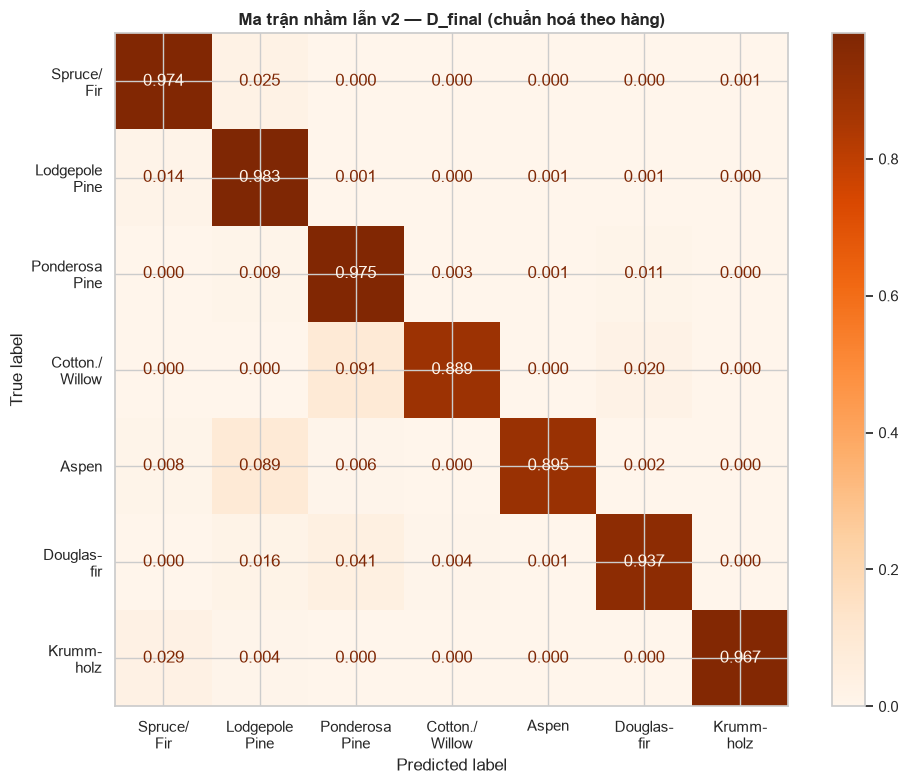

In [34]:
from scipy.stats import chi2

X_final_b = engineer_features_b(X_final_raw, variant=FEAT_VARIANT)
y_final_pred_v2 = rf_v2.predict(X_final_b)
yf = y_final.values


def bootstrap_ci(y_true, y_pred, n_boot=1000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    accs, f1s = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        ii = rng.integers(0, n, n)
        accs[b] = (y_true[ii] == y_pred[ii]).mean()
        f1s[b] = f1_score(y_true[ii], y_pred[ii], average='macro')
    return np.percentile(accs, [2.5, 97.5]), np.percentile(f1s, [2.5, 97.5])


rows = []
for name, yp in [('Bước 4.7 (69.720 mẫu, 300 cây, depth 20)', y_final_pred_old),
                 (f'v2 ({len(y_pool_tr):,} mẫu, {K_FINAL} cây, depth {E4_DEPTH})', y_final_pred_v2)]:
    m = eval_preds(yf, yp)
    ci_acc, ci_f1 = bootstrap_ci(yf, yp)
    row = {'Mô hình': name,
           'Accuracy [KTC 95%]': f"{m['accuracy']:.4f} [{ci_acc[0]:.4f}–{ci_acc[1]:.4f}]",
           'Macro-F1 [KTC 95%]': f"{m['macro_f1']:.4f} [{ci_f1[0]:.4f}–{ci_f1[1]:.4f}]"}
    for c in range(1, 8):
        k = int(((yf == c) & (yp == c)).sum()); n = int((yf == c).sum())
        lo, hi = wilson_ci(k, n)
        row[f'Recall L{c}'] = f"{k / n:.3f} [{lo:.3f}–{hi:.3f}]"
    row['Precision L4'] = f"{m['precision_c4']:.3f}"
    rows.append(row)
final_cmp = pd.DataFrame(rows).set_index('Mô hình').T
print("=== SO SÁNH TRÊN D_final (n = {:,}; lớp 4: {:,}) ===".format(len(yf), int((yf == 4).sum())))
display(final_cmp)

# --- McNemar ---
old_ok, new_ok = (y_final_pred_old == yf), (y_final_pred_v2 == yf)
b01 = int((old_ok & ~new_ok).sum())   # cũ đúng, v2 sai
b10 = int((~old_ok & new_ok).sum())   # cũ sai, v2 đúng
stat = (abs(b01 - b10) - 1) ** 2 / (b01 + b10)
p_mcnemar = chi2.sf(stat, df=1)
print(f"\nMcNemar: cũ đúng/v2 sai = {b01:,}; cũ sai/v2 đúng = {b10:,}; χ² = {stat:.1f}; p = {p_mcnemar:.2e}")

print("\n--- Classification Report v2 — D_final ---")
print(classification_report(yf, y_final_pred_v2, target_names=target_names, digits=4))

fig, ax = plt.subplots(figsize=(10, 8))
cm_v2 = confusion_matrix(yf, y_final_pred_v2, labels=range(1, 8))
ConfusionMatrixDisplay(cm_v2.astype(float) / cm_v2.sum(axis=1, keepdims=True),
                       display_labels=short_names).plot(ax=ax, cmap='Oranges', values_format='.3f')
ax.set_title('Ma trận nhầm lẫn v2 — D_final (chuẩn hoá theo hàng)', fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / 'eval_confusion_final_v2.png', dpi=150, bbox_inches='tight')
plt.show()

## 5B.7. Thí nghiệm E6: Tổng quát hoá sang vùng chưa thấy (Leave-One-Wilderness-Out)
> **Câu hỏi**: Mức tăng của v2 trên D_final (chia ngẫu nhiên) còn lại bao nhiêu khi kiểm thử trên một vùng hoang dã (Wilderness Area) không xuất hiện trong dữ liệu huấn luyện? Dữ liệu UCI không có toạ độ, nên đây chỉ là **phép kiểm tra thay thế** cho đánh giá theo khối không gian `[16]`.
>
> **Thiết kế**:
> - Với mỗi vùng k ∈ {1, 2, 3, 4}: huấn luyện trên 3 vùng còn lại (lấy mẫu con phân tầng tới n mẫu), kiểm thử trên **toàn bộ** vùng k. Thực hiện 3 seed.
> - So sánh 4 cấu hình:

| Mã | Cấu hình | n huấn luyện | Mục đích |
| :---: | :--- | :---: | :--- |
| **A** | Bước 4.7: F0, `max_depth=20`, `balanced_subsample`, 100 cây | 69.720 | Mô hình cũ (100 cây thay vì 300 để giảm chi phí; ở 4.6, số cây ảnh hưởng ≤ 0,001 F1) |
| **B** | v2 (F2, entropy, `max_features=0.35`, `max_depth=None`, 150 cây) | 69.720 | Tách hiệu ứng **cấu hình** khỏi hiệu ứng quy mô dữ liệu |
| **C** | v2 | min(348.608, số mẫu sẵn có) | Mô hình v2 |
| **D** | v2 + `class_weight='balanced_subsample'`, `min_samples_leaf=2` | như C | Phương án ưu tiên Recall lớp 4 từ E5 |

> **Thước đo**: phân bố lớp khác nhau rất mạnh giữa các vùng; đặc biệt **lớp 4 chỉ có ở vùng 4**. Do đó báo cáo: (i) Accuracy trên toàn vùng; (ii) Macro-F1 chỉ trên các lớp **có mặt cả trong huấn luyện và trong vùng kiểm thử**; (iii) tỷ lệ mẫu thuộc lớp chưa từng thấy khi huấn luyện (chắc chắn bị phân loại sai).
>
> **Mốc tham chiếu (chia ngẫu nhiên)**: dự đoán của mô hình Bước 4.7 và v2 (5B.6) trên các dòng D_final thuộc cùng vùng, tính bằng cùng thước đo và cùng tập lớp.

In [35]:
WA_NAMES = {1: 'Rawah', 2: 'Neota', 3: 'Comanche Peak', 4: 'Cache la Poudre'}
wa_all = df_raw[[f'Wilderness_Area_{i}' for i in range(1, 5)]].values.argmax(axis=1) + 1
wa_all = pd.Series(wa_all, index=df_raw.index)

print("--- Bảng chéo lớp × vùng (toàn bộ dữ liệu) ---")
display(pd.crosstab(y_all, wa_all, margins=True))

V2_BASE = {'n_estimators': K_FINAL, 'max_depth': E4_DEPTH, **CFG_B}
E6_CONFIGS = {
    'A': dict(variant='F0', n=len(X_train_raw),
              params={'n_estimators': 100, 'max_depth': 20, 'class_weight': 'balanced_subsample'}),
    'B': dict(variant=FEAT_VARIANT, n=len(X_train_raw), params=V2_BASE),
    'C': dict(variant=FEAT_VARIANT, n=len(y_pool_tr), params=V2_BASE),
    'D': dict(variant=FEAT_VARIANT, n=len(y_pool_tr),
              params={**V2_BASE, 'class_weight': 'balanced_subsample', 'min_samples_leaf': 2}),
}


def region_metrics(y_true, y_pred, seen_classes):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    labels = sorted(set(np.unique(y_true)) & set(seen_classes))
    seen_mask = np.isin(y_true, labels)
    return {
        'acc_all': accuracy_score(y_true, y_pred),
        'macro_f1_seen': f1_score(y_true[seen_mask], y_pred[seen_mask], labels=labels, average='macro'),
        'share_unseen': 1 - seen_mask.mean(),
        'labels_seen': ','.join(map(str, labels)),
    }


X_feat_cache = {v: engineer_features_b(X_all, variant=v) for v in {'F0', FEAT_VARIANT}}

e6_rows = []
t_e6 = time.time()
for k in range(1, 5):
    tr_mask = (wa_all != k).values
    te_mask = ~tr_mask
    y_tr_all, y_te = y_all[tr_mask], y_all[te_mask]
    seen = sorted(y_tr_all.unique())

    # --- Mốc tham chiếu: chia ngẫu nhiên, D_final thuộc vùng k ---
    fin_mask = (wa_all.loc[X_final_raw.index] == k).values
    for ref_name, yp in [('A_ref (Bước 4.7, chia ngẫu nhiên)', y_final_pred_old),
                         ('C_ref (v2, chia ngẫu nhiên)', y_final_pred_v2)]:
        m = region_metrics(y_final.values[fin_mask], yp[fin_mask], seen)
        e6_rows.append({'region': k, 'config': ref_name, 'seed': -1, 'n_train': np.nan,
                        'n_test': int(fin_mask.sum()), **m})

    for cfg_name, cfg in E6_CONFIGS.items():
        n_avail = int(tr_mask.sum())
        n_use = min(cfg['n'], n_avail)
        for seed in STAGE_B_SEEDS:
            if n_use < n_avail:
                idx_tr, _ = train_test_split(np.where(tr_mask)[0], train_size=n_use,
                                             stratify=y_tr_all, random_state=seed)
            else:
                idx_tr = np.where(tr_mask)[0]
            Xf = X_feat_cache[cfg['variant']]
            rf_tmp = RandomForestClassifier(random_state=seed, n_jobs=-1, **cfg['params'])
            rf_tmp.fit(Xf.iloc[idx_tr], y_all.iloc[idx_tr])
            m = region_metrics(y_te, rf_tmp.predict(Xf[te_mask]), seen)
            e6_rows.append({'region': k, 'config': cfg_name, 'seed': seed, 'n_train': n_use,
                            'n_test': int(te_mask.sum()), **m})
            del rf_tmp
            gc.collect()
    print(f"  xong vùng {k} ({WA_NAMES[k]}) — {time.time() - t_e6:.0f}s")

e6_df = pd.DataFrame(e6_rows)
e6_df.to_csv(TABLE_DIR / 'e6_lowo.csv', index=False, encoding='utf-8-sig')
del X_feat_cache
gc.collect()

--- Bảng chéo lớp × vùng (toàn bộ dữ liệu) ---


col_0,1,2,3,4,All
Cover_Type,,,,,
1,105717,18595,87528,0,211840
2,146197,8985,125093,3026,283301
3,0,0,14300,21454,35754
4,0,0,0,2747,2747
5,3781,0,5712,0,9493
6,0,0,7626,9741,17367
7,5101,2304,13105,0,20510
All,260796,29884,253364,36968,581012


  xong vùng 1 (Rawah) — 232s
  xong vùng 2 (Neota) — 556s
  xong vùng 3 (Comanche Peak) — 775s
  xong vùng 4 (Cache la Poudre) — 1089s


0

=== E6: LEAVE-ONE-WILDERNESS-OUT (TB ± SD qua 3 seed; *_ref = chia ngẫu nhiên trên D_final cùng vùng) ===


,region,config,n_train,n_test,acc_mean,acc_sd,f1_seen_mean,f1_seen_sd,share_unseen,labels_seen
0,WA1 (Rawah),A,69720.0000,260796,0.6459,0.0048,0.4025,0.0079,0.0000,"1,2,5,7"
1,WA1 (Rawah),"A_ref (Bước 4.7, chia ngẫu nhiên)",NaN,52087,0.8999,NaN,0.8481,NaN,0.0000,"1,2,5,7"
2,WA1 (Rawah),B,69720.0000,260796,0.5926,0.0017,0.3856,0.0027,0.0000,"1,2,5,7"
3,WA1 (Rawah),C,320216.0000,260796,0.5914,0.0042,0.3814,0.0040,0.0000,"1,2,5,7"
4,WA1 (Rawah),"C_ref (v2, chia ngẫu nhiên)",NaN,52087,0.9782,NaN,0.9620,NaN,0.0000,"1,2,5,7"
5,WA1 (Rawah),D,320216.0000,260796,0.6040,0.0050,0.3929,0.0020,0.0000,"1,2,5,7"
6,WA2 (Neota),A,69720.0000,29884,0.5726,0.0100,0.3695,0.0167,0.0000,"1,2,7"
7,WA2 (Neota),"A_ref (Bước 4.7, chia ngẫu nhiên)",NaN,5892,0.9267,NaN,0.9244,NaN,0.0000,"1,2,7"
8,WA2 (Neota),B,69720.0000,29884,0.5283,0.0069,0.3637,0.0385,0.0000,"1,2,7"
9,WA2 (Neota),C,348608.0000,29884,0.5355,0.0087,0.3998,0.0459,0.0000,"1,2,7"



--- Macro-F1 trên các lớp đã thấy ---


region,WA1 (Rawah),WA2 (Neota),WA3 (Comanche Peak),WA4 (Cache la Poudre),Trung bình 4 vùng
config,,,,,
A,0.4025,0.3695,0.2890,0.2034,0.3161
"A_ref (Bước 4.7, chia ngẫu nhiên)",0.8481,0.9244,0.8320,0.8291,0.8584
B,0.3856,0.3637,0.2695,0.2449,0.3159
C,0.3814,0.3998,0.2609,0.2491,0.3228
"C_ref (v2, chia ngẫu nhiên)",0.9620,0.9856,0.9561,0.9762,0.9700
D,0.3929,0.3447,0.2473,0.2468,0.3079


--- Accuracy toàn vùng (gồm cả mẫu thuộc lớp chưa thấy) ---


region,WA1 (Rawah),WA2 (Neota),WA3 (Comanche Peak),WA4 (Cache la Poudre),Trung bình 4 vùng
config,,,,,
A,0.6459,0.5726,0.6144,0.2328,0.5164
"A_ref (Bước 4.7, chia ngẫu nhiên)",0.8999,0.9267,0.8834,0.8488,0.8897
B,0.5926,0.5283,0.5852,0.2732,0.4948
C,0.5914,0.5355,0.5813,0.2782,0.4966
"C_ref (v2, chia ngẫu nhiên)",0.9782,0.9857,0.9725,0.9683,0.9762
D,0.6040,0.5475,0.5807,0.2772,0.5024


--- Phân rã chênh lệch Macro-F1 (lớp đã thấy) ---


,Bước 4.7: ref − A,v2: ref − C,Lợi thế v2 khi chia ngẫu nhiên (C_ref − A_ref),Lợi thế v2 ở vùng chưa thấy (C − A),Do cấu hình (B − A),Do quy mô dữ liệu (C − B)
region,,,,,,
WA1 (Rawah),0.4456,0.5806,0.1139,-0.0211,-0.0169,-0.0042
WA2 (Neota),0.5549,0.5858,0.0613,0.0303,-0.0058,0.0361
WA3 (Comanche Peak),0.5430,0.6953,0.1241,-0.0282,-0.0195,-0.0087
WA4 (Cache la Poudre),0.6258,0.7271,0.1471,0.0457,0.0416,0.0042
Trung bình 4 vùng,0.5423,0.6472,0.1116,0.0067,-0.0002,0.0069


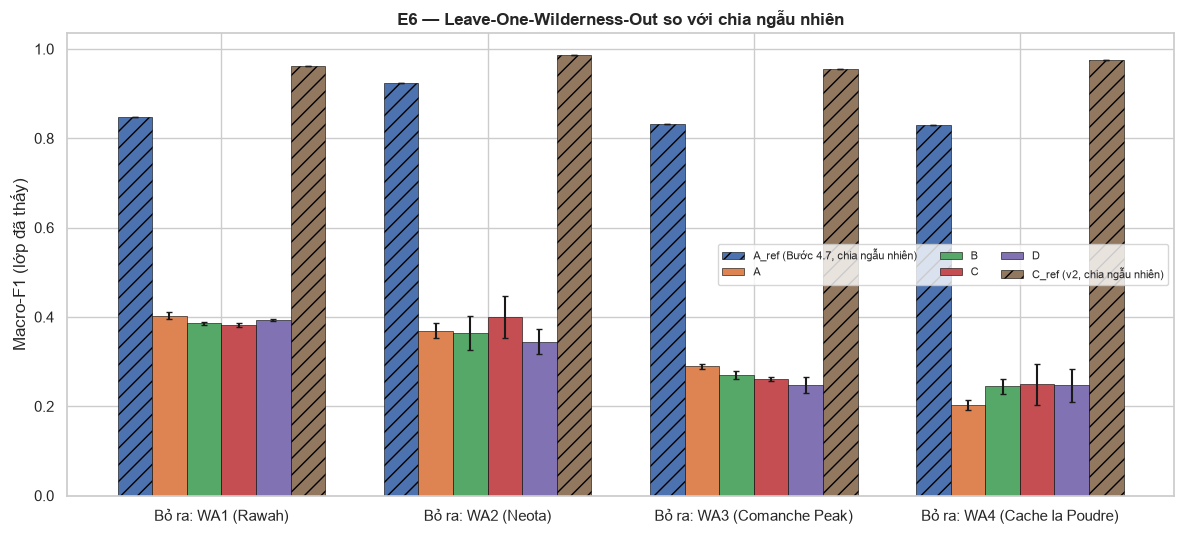

In [36]:
# === TỔNG HỢP E6 ===
e6_sum = (e6_df.groupby(['region', 'config'])
          .agg(n_train=('n_train', 'first'), n_test=('n_test', 'first'),
               acc_mean=('acc_all', 'mean'), acc_sd=('acc_all', 'std'),
               f1_seen_mean=('macro_f1_seen', 'mean'), f1_seen_sd=('macro_f1_seen', 'std'),
               share_unseen=('share_unseen', 'first'), labels_seen=('labels_seen', 'first'))
          .reset_index())
e6_sum['region'] = e6_sum['region'].map(lambda k: f"WA{k} ({WA_NAMES[k]})")
print("=== E6: LEAVE-ONE-WILDERNESS-OUT (TB ± SD qua 3 seed; *_ref = chia ngẫu nhiên trên D_final cùng vùng) ===")
display(e6_sum)

# --- Bảng gọn: Macro-F1 (lớp đã thấy) theo vùng × cấu hình ---
pivot_f1 = e6_sum.pivot(index='config', columns='region', values='f1_seen_mean')
pivot_f1['Trung bình 4 vùng'] = pivot_f1.mean(axis=1)
print("\n--- Macro-F1 trên các lớp đã thấy ---")
display(pivot_f1.round(4))

pivot_acc = e6_sum.pivot(index='config', columns='region', values='acc_mean')
pivot_acc['Trung bình 4 vùng'] = pivot_acc.mean(axis=1)
print("--- Accuracy toàn vùng (gồm cả mẫu thuộc lớp chưa thấy) ---")
display(pivot_acc.round(4))

# --- Mức suy giảm so với chia ngẫu nhiên ---
drop = pd.DataFrame({
    'Bước 4.7: ref − A': pivot_f1.loc['A_ref (Bước 4.7, chia ngẫu nhiên)'] - pivot_f1.loc['A'],
    'v2: ref − C': pivot_f1.loc['C_ref (v2, chia ngẫu nhiên)'] - pivot_f1.loc['C'],
    'Lợi thế v2 khi chia ngẫu nhiên (C_ref − A_ref)': pivot_f1.loc['C_ref (v2, chia ngẫu nhiên)'] - pivot_f1.loc['A_ref (Bước 4.7, chia ngẫu nhiên)'],
    'Lợi thế v2 ở vùng chưa thấy (C − A)': pivot_f1.loc['C'] - pivot_f1.loc['A'],
    'Do cấu hình (B − A)': pivot_f1.loc['B'] - pivot_f1.loc['A'],
    'Do quy mô dữ liệu (C − B)': pivot_f1.loc['C'] - pivot_f1.loc['B'],
})
print("--- Phân rã chênh lệch Macro-F1 (lớp đã thấy) ---")
display(drop.round(4))

fig, ax = plt.subplots(figsize=(12, 5.5))
order = ['A_ref (Bước 4.7, chia ngẫu nhiên)', 'A', 'B', 'C', 'D', 'C_ref (v2, chia ngẫu nhiên)']
regions = [c for c in pivot_f1.columns if c != 'Trung bình 4 vùng']
w = 0.13
for j, cfg in enumerate(order):
    sub = e6_sum.set_index(['config', 'region'])
    vals = [sub.loc[(cfg, r), 'f1_seen_mean'] for r in regions]
    errs = [sub.loc[(cfg, r), 'f1_seen_sd'] if not np.isnan(sub.loc[(cfg, r), 'f1_seen_sd']) else 0 for r in regions]
    ax.bar(np.arange(len(regions)) + (j - 2.5) * w, vals, w, yerr=errs, capsize=2, label=cfg,
           hatch='//' if 'ref' in cfg else None, edgecolor='black', linewidth=0.4)
ax.set_xticks(np.arange(len(regions)))
ax.set_xticklabels([f"Bỏ ra: {r}" for r in regions])
ax.set_ylabel('Macro-F1 (lớp đã thấy)')
ax.set_title('E6 — Leave-One-Wilderness-Out so với chia ngẫu nhiên', fontweight='bold')
ax.legend(fontsize=8, ncol=3)
plt.tight_layout()
plt.savefig(FIG_DIR / 'e6_lowo.png', dpi=150, bbox_inches='tight')
plt.show()

## 5B.8. Tổng kết Bước 5B
> Mọi số liệu dưới đây là **số đo thực nghiệm** của lần chạy này (seed 42, 7, 2024; sklearn 1.9.1). Các số đo ở mục 1–3 được tính trên D_val, còn mục 4 trên D_final (đánh giá một lần).

### 1. E4 — Quy mô dữ liệu là yếu tố có tác động lớn nhất trong không gian khảo sát
- Với `max_depth=None`, Macro-F1 tăng từ 0,8483 ± 0,0015 (25% D_pool, ≈ quy mô Bước 4) lên 0,9207 ± 0,0004 (100% D_pool, 348.608 mẫu). Đường cong vẫn còn dốc ở mức 75% → 100% (+0,0113), nên chưa quan sát thấy điểm bão hoà trong phạm vi dữ liệu hiện có.
- `max_depth=20` cho F1 thấp hơn ở mọi mức ≥ 25% (0,8904 ở 100%). Giới hạn độ sâu hạn chế lợi ích của dữ liệu lớn.
- Ngoại lệ: với `max_depth=20` + `balanced_subsample`, Recall lớp 5 cao hơn (0,90 so với 0,78 ở 100%), nhưng Precision các lớp khác thấp hơn và Macro-F1 tổng thể thấp hơn.

### 2. E2b / E3-D — Đặc trưng
- **F2** (thêm 6 tổ hợp khoảng cách) nâng Macro-F1 thêm +0,0236 so với F0, lớn hơn khoảng 30 lần độ lệch chuẩn giữa các seed. Thêm vùng khí hậu/địa chất (F3) không tạo khác biệt có ý nghĩa (−0,0000), F4 ≈ F2 (+0,0006, < 1 SD). Theo quy tắc ít cột nhất trong ngưỡng, **chọn F2 (26 cột)**.
- F1 (bỏ `Aspect_Sin`, `Delta_Hillshade`) tăng nhẹ (+0,0078) so với F0. Phương án F1+F2 chưa được thử; đây là ứng viên cho một vòng ablation tiếp theo.

### 3. E5 mở rộng — Siêu tham số
- `criterion='entropy'` cho F1 cao hơn `gini` một cách nhất quán ở cả 4 mức `max_features` (+0,005 đến +0,007); `max_features=0.35` (≈ 9 cột) là mức tốt nhất trong lưới.
- Ba cấu hình đứng đầu chênh nhau ≤ 0,0017 F1. Quy tắc "ít nút nhất trong ngưỡng 1 SD" chọn `class_weight=None, min_samples_leaf=1` (F1 = 0,9526 ± 0,0005).
- **Đánh đổi cần lưu ý**: cấu hình `balanced_subsample, min_samples_leaf=2` có F1 thấp hơn 0,0017 nhưng Recall lớp 4 cao hơn (0,897 ± 0,006 so với 0,858 ± 0,010). Nếu mục tiêu đề tài ưu tiên độ nhạy lớp 4 hơn Macro-F1 thì nên chọn cấu hình này.
- Số cây: F1 trên D_val gần như không đổi từ 150 → 300 cây (chênh ≤ 0,0009). Chọn **150 cây**; file mô hình còn 76 MB (so với 470 MB của mô hình Bước 4.7).

### 4. Đánh giá một lần trên D_final (n = 116.202; lớp 4 = 549)
| Chỉ số | Bước 4.7 | v2 |
| :--- | :---: | :---: |
| Accuracy [KTC 95% bootstrap] | 0,8908 [0,8891–0,8926] | 0,9754 [0,9745–0,9764] |
| Macro-F1 [KTC 95% bootstrap] | 0,8343 [0,8287–0,8397] | 0,9542 [0,9506–0,9574] |
| Recall lớp 4 [Wilson] | 0,763 [0,726–0,797] | 0,889 [0,860–0,913] |
| Recall lớp 5 [Wilson] | 0,688 [0,667–0,708] | 0,895 [0,881–0,908] |
| Precision lớp 4 | 0,826 | 0,926 |

Kiểm định McNemar: 10.570 mẫu chỉ v2 đúng, so với 738 mẫu chỉ mô hình cũ đúng (p < 10⁻¹⁰⁰). Khoảng tin cậy của hai mô hình không giao nhau ở mọi lớp.

### 5. E6 — Leave-One-Wilderness-Out (3 seed; huấn luyện trên 3 vùng, kiểm thử trên vùng còn lại)
| Macro-F1 (lớp đã thấy) | WA1 | WA2 | WA3 | WA4 | TB 4 vùng |
| :--- | :---: | :---: | :---: | :---: | :---: |
| Bước 4.7 — chia ngẫu nhiên (tham chiếu) | 0,848 | 0,924 | 0,832 | 0,829 | 0,858 |
| v2 — chia ngẫu nhiên (tham chiếu) | 0,962 | 0,986 | 0,956 | 0,976 | 0,970 |
| A: cấu hình Bước 4.7, vùng chưa thấy | 0,403 ± 0,008 | 0,370 ± 0,017 | 0,289 ± 0,007 | 0,203 ± 0,011 | 0,316 |
| C: v2, vùng chưa thấy | 0,381 ± 0,004 | 0,400 ± 0,046 | 0,261 ± 0,005 | 0,249 ± 0,046 | 0,323 |

- **Suy giảm mạnh khi chuyển vùng**: Macro-F1 giảm khoảng 0,54 (Bước 4.7) và 0,65 (v2) so với chia ngẫu nhiên. Accuracy trung bình 4 vùng còn 0,50–0,52.
- **Lợi thế của v2 hầu như không chuyển sang vùng mới**: khi chia ngẫu nhiên, v2 hơn Bước 4.7 khoảng +0,112 Macro-F1; ở vùng chưa thấy chênh lệch chỉ còn +0,007. Dấu của chênh lệch thay đổi theo vùng (âm ở WA1, WA3; dương ở WA2, WA4), và ở WA2, WA4 chênh lệch nằm trong khoảng độ lệch chuẩn. Phân rã B − A (cấu hình) và C − B (quy mô dữ liệu) đều có trung bình gần 0.
- Phương án D (`balanced_subsample`, `min_samples_leaf=2`) không cải thiện so với C ở vùng chưa thấy (0,308 so với 0,323).
- WA4: 7,4% mẫu thuộc lớp 4, lớp chỉ có ở vùng này, nên khi WA4 bị bỏ ra thì chắc chắn bị phân loại sai; con số này được báo cáo riêng và không tính vào Macro-F1 trên các lớp đã thấy.

**Diễn giải**:
- Kết quả phù hợp với giả thuyết rằng phần lớn mức tăng của v2 trên D_final đến từ việc khai thác mẫu lân cận trong cùng vùng: các ô 30 m liền kề và các đặc trưng gắn với vị trí như khoảng cách tới đường và tới điểm cháy, cùng các tổ hợp của chúng trong F2. Phần tăng này không đến từ quy luật sinh thái tổng quát hơn.
- Tuy vậy, E6 gộp hai yếu tố: (i) tự tương quan không gian và (ii) dịch chuyển phân bố thực sự giữa các vùng (tỷ lệ lớp, dải cao độ, loại đất khác nhau; cột `Wilderness_Area_k` của vùng bị bỏ ra luôn bằng 0 khi huấn luyện). Vì vậy E6 là cận dưới khắt khe, chưa tách được phần đóng góp của từng yếu tố.
- **Hệ quả cho Bước 6**: luật trích xuất từ cây đại diện nên được trình bày là mô tả hành vi của RF **trong phạm vi 4 vùng nghiên cứu**, không phải quy luật sinh thái áp dụng được sang vùng khác. `[GIẢ THUYẾT]` Loại các đặc trưng gắn với vị trí (Roadways, Fire_Points và tổ hợp của chúng) có thể cải thiện kết quả E6 và cho luật có ý nghĩa sinh thái rõ hơn; cần kiểm chứng bằng ablation.

### 6. Hạn chế và diễn giải thận trọng
1. **Phạm vi áp dụng**: mọi chỉ số ở mục 1–4 chỉ đúng cho dự đoán **bên trong 4 vùng nghiên cứu** với phép chia ngẫu nhiên. Theo E6 (mục 5), chúng **không** phản ánh năng lực áp dụng sang vùng địa lý chưa thấy.
2. Các tổ hợp khoảng cách của F2 là heuristic thực hành, chưa có cơ sở bình duyệt; ý nghĩa sinh thái của chúng (ví dụ tổng khoảng cách tới nguồn nước và điểm cháy) cần được biện luận nếu chúng xuất hiện trong luật của cây đại diện.
3. Rừng v2 sâu hơn (≈ 26.900 nút/cây, so với ≈ 8.600–15.900 nút/cây đo ở E4 với `max_depth=20` trên 35K–87K mẫu, tức quy mô gần mô hình Bước 4.7), nên một cây đại diện độ sâu 3–6 có thể đạt Fidelity thấp hơn so với khi xấp xỉ mô hình cũ. `[CẦN ĐO]` ở E7.
4. Độ lệch chuẩn qua seed không bao gồm biến thiên do chọn D_val cố định.

### 7. Đầu vào cho Bước 6
- Mô hình chủ: `models/rf_covertype_final_v2.joblib`; cấu hình và danh sách 26 đặc trưng: `models/rf_v2_config.json`; hàm biến đổi: `engineer_features_b(df, variant='F2')`.
- Chỉ số phân chia: `models/splits_v2.npz`. Dùng `idx_val` (D_val, rời tập huấn luyện RF) làm bể truy vấn để huấn luyện cây đại diện theo dự đoán của RF; dùng `idx_final` (D_final) để đo Fidelity và Accuracy của cây.